# Проверка моделей: CatBoost, гибрид, категоризация

Здесь мы проверяем три части сервиса прогноза денежных потоков на компаниях, которых модель не видела при обучении.

## Метрики и зачем они нужны

Разрывов в данных мало: они есть примерно в 17% проверочных окон. Поэтому обычная «доля верных ответов» нам не подходит. Модель, которая всегда отвечает «разрыва не будет», была бы права в 83% случаев и при этом ничем бы не помогла. Мы смотрим на метрики, которые показывают, как модель справляется именно с редким событием.

| Метрика | Что это простыми словами | Зачем она нам |
|---|---|---|
| Precision | Из всех тревог модели сколько оказались настоящими | Чтобы предприниматель не получал ложных тревог |
| Recall | Из всех настоящих разрывов сколько модель нашла | Пропущенный разрыв обходится дороже ложной тревоги |
| F1 | Одно число из precision и recall | Чтобы сравнивать модели одним числом |
| Матрица ошибок | Таблица из четырёх исходов: нашли разрыв, пропустили, ложная тревога, верно «всё спокойно» | Видно, какие именно ошибки делает модель |
| ROC-AUC | Насколько хорошо модель отличает окна с разрывом от окон без него. 0,5 это как случайно, 1 это идеально | Не зависит от выбранного порога тревоги |
| PR-AUC | То же самое, но точнее, когда событие редкое | Главная метрика при редких разрывах |
| Brier | Насколько вероятности совпадают с жизнью: если модель говорит 70%, сбывается ли это примерно в 70% случаев. Чем меньше, тем лучше | Нам нужна вероятность разрыва, а не только «да» или «нет» |
| RMSE, MAE | Средняя ошибка прогноза остатка. Считаем в дневных оборотах компании: «ошибка 3» значит, что промахнулись на три дня обычных трат | Чтобы сравнивать маленькую и большую компанию |
| Accuracy, macro-F1 | Для категорий операций: доля верных ответов и средний F1 по всем категориям | macro-F1 учитывает и редкие категории, а не только частые |

## Что такое «гибрид»

Гибрид это наша основная модель прогноза остатка. Она не обучается на других компаниях, а считает по истории самой компании. Остаток на каждый будущий день складывается из трёх частей:

1. **Известные события.** Всё, что известно заранее: регулярные платежи (аренда, зарплата, кредит), налоги по календарю (ЕНП до 28-го), выставленные счета, события, которые ввёл предприниматель. Каждое событие ставится на свою дату и свою сумму.
2. **Розничная выручка** (эквайринг, СБП, наличные). Берём средний уровень отдельно по каждому дню недели: понедельник не похож на пятницу.
3. **Всё остальное.** Средний приход и средний расход за день.

Чтобы учесть неопределённость, мы 1000 раз «проигрываем» будущее методом Монте-Карло, добавляя реальные отклонения из прошлого. Из 1000 вариантов берём коридор P10–P90 (в нём 80% вариантов) и вероятность разрыва: долю вариантов, где остаток ушёл ниже нуля.

Название «гибрид» потому, что модель соединяет расчёт «поштучно» (события) и расчёт «в среднем» (статистика).

## Что такое CatBoost

CatBoost это градиентный бустинг: много небольших деревьев решений, и каждое исправляет ошибки предыдущих. Одна модель обучается сразу на всех компаниях и прогнозирует, сколько денег суммарно придёт и уйдёт за следующие h дней. Она хорошо переносит опыт других компаний, но не знает про конкретные события конкретной компании (счёт, обещанный платёж), их знает только гибрид. Поэтому мы сравниваем три варианта: гибрид, CatBoost и ансамбль (среднее двух).

## Как проверяли

- **Кросс-валидация по компаниям** (5 фолдов, отрасли поровну). Каждая компания хотя бы раз попадает в тест, а модель её при этом не видела. Так мы проверяем перенос на новые компании.
- **Разрез по времени.** Обучающие окна заканчиваются раньше первого проверочного.
- Проверочные окна: 12 дат прогноза с шагом 5 рабочих дней, горизонт 30 дней. Окна с «дырами» в выписке не оцениваем.
- **Разрыв** это день, когда остаток ниже нуля, или скрытый разрыв: остаток ушёл бы в минус, если бы владелец не довнёс деньги. Окна, где разрыв уже идёт в момент прогноза, из классификации исключены.
- **Порог тревоги** для каждого фолда подбираем по остальным фолдам.
- Ограничение: категории операций размечаются по всей выписке, поэтому слой «история контрагента» видит и более поздние операции. Влияние небольшое, потому что правила по назначению покрывают 99,99% операций.

## Результаты (150 компаний, 1 594 окна, в 268 из них был разрыв)

| Модель | ROC-AUC | PR-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| CatBoost | 0,894 | 0,605 | 0,569 | 0,49 | 0,68 |
| Гибрид | 0,887 | 0,636 | 0,587 | 0,48 | 0,77 |
| Ансамбль гибрида и CatBoost | 0,902 | 0,662 | 0,594 | 0,53 | 0,68 |

- Лучше всех разрывы находит ансамбль. Разница в F1 между моделями небольшая, её нельзя считать надёжной. По PR-AUC и ROC-AUC ансамбль стабильно выше.
- Точную сумму остатка через 30 дней не угадывает ни одна модель: у всех трёх ошибка около 21 дневного оборота, различия в пределах погрешности. Мешают редкие крупные платежи, которых нет в истории. Польза прогноза в раннем предупреждении за 7–9 рабочих дней.
- Категоризация на искажённых назначениях: accuracy 0,946, macro-F1 0,948 (на обычных назначениях 1,00, потому что данные сгенерированы по шаблонам). Слабое место: непонятные операции уходят в «поставщиков» (precision 0,59).


In [1]:
import glob
import json
import os
import subprocess
import sys
import time
import warnings
import zipfile

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "catboost", "kaggle", "pytest"], check=True)
    if not os.path.exists("ledokol"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/HopenPen/ledokol.git"], check=True)
    sys.path.insert(0, "ledokol/backend")
else:  # локально: ноутбук лежит в analytics/ рядом с backend/
    for p in ("../backend", "backend"):
        sys.path.insert(0, os.path.abspath(p))

import matplotlib.pyplot as plt  # noqa: E402
from catboost import CatBoostRegressor, Pool  # noqa: E402
from matplotlib.colors import LinearSegmentedColormap  # noqa: E402
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,  # noqa: E402
                             classification_report, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold  # noqa: E402

from app.backtest.runner import _actual_gap_days  # noqa: E402
from app.domain.calendar import is_working_day, next_working_day  # noqa: E402
from app.domain.categories import CATEGORIES, EXCLUDED_FROM_FORECAST  # noqa: E402
from app.domain.categorize import TextClassifier  # noqa: E402
from app.domain.forecast import fit, forecast  # noqa: E402
from app.domain.ingest import read_statement  # noqa: E402
from app.domain.ml_flow import NON_FEATURES, adversarial_filter, make_cum_rows, mix_weights, operational_flow  # noqa: E402
from app.domain.pipeline import prepare_company, split_by_company  # noqa: E402

### Оформление графиков
У каждой модели свой цвет, на всех графиках он одинаковый. Матрицы ошибок нарисованы одной синей шкалой: чем темнее клетка, тем больше значение.

In [2]:
PAL = {"CatBoost": "#2a78d6", "Гибрид": "#eb6834", "Ансамбль": "#e87ba4"}
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "figure.dpi": 110,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK, "font.size": 10,
})

In [3]:
CFG = {
    "horizon": 30,
    "eval_cutoffs": 12, "eval_step": 5,      # как в бэктесте приложения, только отсечек больше
    "min_history": 60,
    "n_folds": 5,
    "train_step": 3,                          # шаг отсечек в обучении (окна перекрываются — это нормально)
    "train_horizons": [1, 2, 3, 5, 7, 10, 14, 20, 25, 30],
    "val_frac": 0.15,                         # доля обучающих компаний под раннюю остановку
    "quantiles": [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95],
    "iterations": 1500, "learning_rate": 0.06, "depth": 6, "l2_leaf_reg": 5.0, "od_wait": 100, "seed": 7,
    "case_share": 0.5, "max_p_external": 0.8, "ext_step": 7,
    "n_sims": 300,                            # траекторий Монте-Карло у гибрида
    "gap_threshold": 0.5,                     # предупреждаем, если вероятность нехватки ≥ 50%
    "bootstrap": 500,
    "max_companies": None,                    # для быстрого прогона: например 30
}
CFG.update(json.loads(os.environ.get("CFG_OVERRIDES", "{}")))
H = CFG["horizon"]
QS = CFG["quantiles"]
CAT_FEATURES = ["industry", "target_dow", "source"]

## 1. Данные кейса
В Colab загрузите `cashflow_dataset_participants.zip` (или положите распакованную папку и задайте `CASE_DIR`).

In [4]:
def find_case_dir() -> str | None:
    for base in [os.environ.get("CASE_DIR", ""), ".", "data", "/content", "/content/data", "../data"]:
        if base and os.path.isdir(base):
            hits = glob.glob(os.path.join(base, "**", "all_operations.csv"), recursive=True)
            if hits:
                return os.path.dirname(hits[0])
    return None


root = find_case_dir()
if root is None:
    zips = glob.glob("*.zip") + glob.glob("/content/*.zip")
    if not zips and IN_COLAB:
        from google.colab import files
        zips = [k for k in files.upload() if k.endswith(".zip")]
    for z in zips:
        zipfile.ZipFile(z).extractall("data")
    root = find_case_dir()
assert root, "Не найден all_operations.csv"
raw = read_statement(open(os.path.join(root, "all_operations.csv"), "rb").read())
companies = pd.read_csv(os.path.join(root, "companies.csv"), sep=";", encoding="utf-8-sig", dtype=str)
INDUSTRY = dict(zip(companies["company_id"], companies["industry"]))

t0 = time.time()
preps = {cid: prepare_company(df) for cid, df in sorted(split_by_company(raw).items())}
if CFG["max_companies"]:
    preps = dict(list(preps.items())[: CFG["max_companies"]])
print(f"Кейс: {len(preps)} компаний, {len(raw):,} операций; подготовка {time.time() - t0:.0f} с")

Кейс: 150 компаний, 222,420 операций; подготовка 8 с


## 2. Проверочные окна и правильные ответы
Для каждого окна запоминаем фактический остаток, остаток без денег владельца и переводов между своими счетами (их прогноз не закладывает) и был ли в окне разрыв.

In [5]:
def eval_positions(prep) -> list[int]:
    panel, n = prep.panel.reset_index(drop=True), len(prep.panel)
    out = []
    for k in range(CFG["eval_cutoffs"]):
        pos = n - 1 - H - k * CFG["eval_step"]
        if pos < CFG["min_history"]:
            break
        if not panel["after_gap"].iloc[pos + 1: pos + 1 + H].any():
            out.append(pos)
    return out


windows = []
for cid, prep in preps.items():
    panel, ops = prep.panel.reset_index(drop=True), prep.ops
    excl = ops[ops["category"].isin(EXCLUDED_FROM_FORECAST) & ops["quality"].ne("duplicate")] \
        .groupby("operation_date")["signed"].sum()
    for pos in eval_positions(prep):
        win = panel.iloc[pos + 1: pos + 1 + H]
        actual = win["balance"].to_numpy()
        hist_ops = ops[ops["operation_date"].le(panel.loc[pos, "date"])]
        out_flow = hist_ops[hist_ops["direction"].eq("out") & hist_ops["operation_date"].isin(panel["date"].iloc[:pos + 1].tail(60))]
        gap_days = _actual_gap_days(win, ops)
        windows.append({
            "company": cid, "industry": INDUSTRY.get(cid, "unknown"), "pos": pos, "cutoff": panel.loc[pos, "date"],
            "bal0": float(panel.loc[pos, "balance"]), "actual": actual,
            "actual_oper": actual - np.cumsum(win["date"].map(excl).fillna(0.0).to_numpy()),
            "scale": max(out_flow["amount"].sum() / 60, 1.0),       # средний дневной расход — единица ошибки
            "gap_actual": bool(gap_days.size), "first_gap_wd": int(gap_days[0]) + 1 if gap_days.size else None,
            "ongoing": bool(panel.loc[pos, "balance"] < 0),
        })
W = pd.DataFrame(windows)
EVAL_START = W["cutoff"].min()
print(f"Окон: {len(W)} по {W['company'].nunique()} компаниям; с разрывом: {int(W['gap_actual'].sum())} "
      f"(уже идёт в момент прогноза: {int(W['ongoing'].sum())}); первое проверочное окно: {EVAL_START.date()}")

Окон: 1653 по 143 компаниям; с разрывом: 327 (уже идёт в момент прогноза: 59); первое проверочное окно: 2025-06-20


## 3. Гибрид на тех же окнах
Гибрид не обучается на других компаниях, он считает по истории самой компании. Поэтому считаем его сразу по всем окнам. Модель видит только историю до даты прогноза.

In [6]:
t0 = time.time()
hyb = {k: [] for k in ("p10", "p50", "p90", "prob")}
for w in windows:
    prep = preps[w["company"]]
    panel, ops = prep.panel.reset_index(drop=True), prep.ops
    hist_ops, hist_panel = ops[ops["operation_date"].le(w["cutoff"])], panel.iloc[: w["pos"] + 1]
    m = fit(hist_ops, hist_panel)
    res = forecast(m, [], horizon=H, n_sims=CFG["n_sims"], seed=CFG["seed"])
    for k, attr in (("p10", "p10"), ("p50", "p50"), ("p90", "p90"), ("prob", "prob_below")):
        hyb[k].append(np.array([getattr(p, attr) for p in res.points]))
for k, v in hyb.items():
    W[f"hyb_{k}"] = v
print(f"Гибрид посчитан за {time.time() - t0:.0f} с")

Гибрид посчитан за 114 с


## 4. Внешние российские данные (по желанию)
В обучение можно добавить продажи сети 1С (Kaggle, нужен файл `kaggle.json`). Внешние окна проходят фильтр: оставляем только похожие на наши, а вес наших данных не меньше 50%.

Проверка на розничной выручке прироста не показала, поэтому по умолчанию ничего не добавляется. Датасет MBD (Сбер) не подошёл: даты в нём перемешаны и нет направления денег.

In [7]:
def load_1c_daily() -> dict[str, pd.Series]:
    """Выручка «магазин × рабочий день»; продажи выходного дня — на ближайший рабочий (как эквайринг)."""
    path = glob.glob("**/sales_train.csv", recursive=True)
    if not path:
        token = "kaggle.json" if os.path.exists("kaggle.json") else os.path.expanduser("~/.kaggle/kaggle.json")
        if not os.path.exists(token):
            print("1С: нет kaggle.json и sales_train.csv — учим только на кейсе")
            return {}
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        if token == "kaggle.json":
            os.replace("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
        subprocess.run(["kaggle", "competitions", "download", "-c", "competitive-data-science-predict-future-sales",
                        "-f", "sales_train.csv", "-p", "1c"], check=False)
        for z in glob.glob("1c/*.zip"):
            zipfile.ZipFile(z).extractall("1c")
        path = glob.glob("**/sales_train.csv", recursive=True)
        if not path:
            print("1С: скачать не удалось — примите правила соревнования на Kaggle")
            return {}
    s = pd.read_csv(path[0])
    s["date"] = pd.to_datetime(s["date"], format="%d.%m.%Y")
    s["revenue"] = s["item_price"].clip(lower=0) * s["item_cnt_day"]
    s["date"] = s["date"].map(lambda d: pd.Timestamp(next_working_day(d.date())))
    out = {}
    for shop, g in s.groupby("shop_id"):
        daily = g.groupby("date")["revenue"].sum()
        days = pd.DatetimeIndex([d for d in pd.date_range(daily.index.min(), daily.index.max()) if is_working_day(d.date())])
        series = daily.reindex(days, fill_value=0.0)
        if len(series) > 250 and (series > 0).mean() > 0.8:
            out[f"1c_{shop}"] = series
    print(f"1С: магазинов {len(out)}")
    return out


onec = load_1c_daily()
ext_all = pd.concat([make_cum_rows(sr, "Розница (1С)", step=CFG["ext_step"], source="1c_retail", company=cid,
                                   horizons=CFG["train_horizons"]) for cid, sr in onec.items()],
                    ignore_index=True) if onec else pd.DataFrame()

1С: магазинов 49


## 5. CatBoost: обучение по фолдам
На каждом фолде обучаем две модели:
- **RMSE**: прогноз суммарного потока за h дней (среднее, потому что остаток складывается из потоков);
- **MultiQuantile** (9 квантилей): коридор P10–P90 и вероятность того, что остаток уйдёт ниже нуля.

Остаток через h дней = остаток на дату прогноза + масштаб компании × прогноз.

In [8]:
flows = {cid: operational_flow(p) for cid, p in preps.items()}
gaps_mask = {cid: p.panel["after_gap"].to_numpy() for cid, p in preps.items()}


def train_rows(cids) -> pd.DataFrame:
    frames = [make_cum_rows(flows[c], INDUSTRY.get(c, "unknown"), step=CFG["train_step"], min_history=CFG["min_history"],
                            after_gap=gaps_mask[c], company=c, horizons=CFG["train_horizons"],
                            max_target_date=EVAL_START) for c in cids]
    return pd.concat([f for f in frames if len(f)], ignore_index=True)


def X(df: pd.DataFrame, force_case: bool = False) -> pd.DataFrame:
    x = df.drop(columns=[c for c in NON_FEATURES if c in df.columns])
    return x.assign(source="case") if force_case else x


def fit_cb(loss: str, tr: pd.DataFrame, va: pd.DataFrame) -> CatBoostRegressor:
    m = CatBoostRegressor(loss_function=loss, eval_metric=loss, iterations=CFG["iterations"],
                          learning_rate=CFG["learning_rate"], depth=CFG["depth"], l2_leaf_reg=CFG["l2_leaf_reg"],
                          random_seed=CFG["seed"], od_type="Iter", od_wait=CFG["od_wait"], use_best_model=True,
                          verbose=False, thread_count=-1)
    m.fit(Pool(X(tr), tr["y"], cat_features=CAT_FEATURES, weight=mix_weights(tr, CFG["case_share"])),
          eval_set=Pool(X(va, True), va["y"], cat_features=CAT_FEATURES))
    return m


Q_LOSS = "MultiQuantile:alpha=" + ",".join(map(str, QS))
ids = np.array(sorted(preps))
sgkf = StratifiedGroupKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=CFG["seed"])
fold_of = {}
for f, (_, te) in enumerate(sgkf.split(ids, [INDUSTRY.get(c, "unknown") for c in ids], groups=ids)):
    fold_of.update({c: f for c in ids[te]})
W["fold"] = W["company"].map(fold_of)

CURVES = []                                          # кривые обучения по фолдам
cb_mean, cb_q = [None] * len(W), [None] * len(W)
importances, fold_log = [], []
rng = np.random.default_rng(CFG["seed"])
for f in range(CFG["n_folds"]):
    t0 = time.time()
    train_ids = [c for c in ids if fold_of[c] != f]
    val_ids = set(rng.choice(train_ids, size=max(2, int(len(train_ids) * CFG["val_frac"])), replace=False))
    rows_all = train_rows(train_ids)
    tr, va = rows_all[~rows_all["company"].isin(val_ids)], rows_all[rows_all["company"].isin(val_ids)]
    lo, hi = tr["y"].quantile([0.005, 0.995])                 # обрезка выбросов цели — по обучающей части
    tr, va = tr.assign(y=tr["y"].clip(lo, hi)), va.assign(y=va["y"].clip(lo, hi))
    n_ext = 0
    if len(ext_all):
        ext = adversarial_filter(tr, ext_all, max_p_external=CFG["max_p_external"])
        n_ext = len(ext)
        tr = pd.concat([tr, ext.assign(y=ext["y"].clip(lo, hi))], ignore_index=True)
    m_mean, m_q = fit_cb("RMSE", tr, va), fit_cb(Q_LOSS, tr, va)
    importances.append(pd.Series(m_mean.get_feature_importance(), index=X(tr).columns))
    if f == 0:
        curves = m_mean.get_evals_result()                   # кривые обучения — для проверки на переобучение
    CURVES.append({"mean": m_mean.get_evals_result(), "q": m_q.get_evals_result(),
                   "best_mean": m_mean.get_best_iteration(), "best_q": m_q.get_best_iteration()})
    test_y, test_p = [], []
    for i in np.flatnonzero(W["fold"].eq(f)):
        w = W.iloc[i]
        rows = make_cum_rows(flows[w["company"]], w["industry"], positions=[w["pos"]], company=w["company"])
        if len(rows) < H:                                    # окно задело конец ряда — не бывает, но проверим
            continue
        p_mean = np.asarray(m_mean.predict(X(rows, True)))
        cb_mean[i] = w["bal0"] + rows["scale"].iloc[0] * p_mean
        cb_q[i] = w["bal0"] + rows["scale"].iloc[0] * np.sort(np.asarray(m_q.predict(X(rows, True))), axis=1)
        test_y.append(rows["y"].clip(lo, hi).to_numpy())
        test_p.append(p_mean)
    rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))  # noqa: E731
    fold_log.append({"фолд": f, "компаний в обучении": len(train_ids) - len(val_ids), "строк кейса": int(tr["source"].eq("case").sum()),
                     "строк 1С": n_ext, "итераций RMSE": m_mean.tree_count_, "итераций квантилей": m_q.tree_count_,
                     "RMSE обучение": rmse(tr["y"], m_mean.predict(X(tr))),
                     "RMSE ранняя остановка": rmse(va["y"], m_mean.predict(X(va, True))),
                     "RMSE тест": rmse(np.concatenate(test_y), np.concatenate(test_p)),
                     "секунд": round(time.time() - t0)})
    print(fold_log[-1])
W["cb_mean"], W["cb_q"] = cb_mean, cb_q
W = W[W["cb_mean"].notna()].reset_index(drop=True)
FOLDS = pd.DataFrame(fold_log)
FOLDS.round(3)

{'фолд': 0, 'компаний в обучении': 102, 'строк кейса': 29695, 'строк 1С': 0, 'итераций RMSE': 190, 'итераций квантилей': 162, 'RMSE обучение': 4.144568739706181, 'RMSE ранняя остановка': 4.568020846291059, 'RMSE тест': 5.698932129318631, 'секунд': 38}


{'фолд': 1, 'компаний в обучении': 102, 'строк кейса': 31147, 'строк 1С': 0, 'итераций RMSE': 248, 'итераций квантилей': 156, 'RMSE обучение': 3.6449120932388905, 'RMSE ранняя остановка': 5.022233846822487, 'RMSE тест': 5.793323742371772, 'секунд': 41}


{'фолд': 2, 'компаний в обучении': 102, 'строк кейса': 29146, 'строк 1С': 30, 'итераций RMSE': 172, 'итераций квантилей': 139, 'RMSE обучение': 3.5575478593292975, 'RMSE ранняя остановка': 4.980226872669232, 'RMSE тест': 6.698076593062417, 'секунд': 35}


{'фолд': 3, 'компаний в обучении': 102, 'строк кейса': 29700, 'строк 1С': 0, 'итераций RMSE': 757, 'итераций квантилей': 173, 'RMSE обучение': 3.097743881465305, 'RMSE ранняя остановка': 4.960355145614886, 'RMSE тест': 6.395210984065305, 'секунд': 62}


{'фолд': 4, 'компаний в обучении': 102, 'строк кейса': 30873, 'строк 1С': 0, 'итераций RMSE': 102, 'итераций квантилей': 97, 'RMSE обучение': 4.319390067803054, 'RMSE ранняя остановка': 4.599930314459941, 'RMSE тест': 6.853612214243879, 'секунд': 31}


,фолд,компаний в обучении,строк кейса,строк 1С,итераций RMSE,итераций квантилей,RMSE обучение,RMSE ранняя остановка,RMSE тест,секунд
0,0,102,29695,0,190,162,4.145,4.568,5.699,38
1,1,102,31147,0,248,156,3.645,5.022,5.793,41
2,2,102,29146,30,172,139,3.558,4.980,6.698,35
3,3,102,29700,0,757,173,3.098,4.960,6.395,62
4,4,102,30873,0,102,97,4.319,4.600,6.854,31


### Проверка на переобучение

Переобучение значит, что модель запомнила обучающие компании и на новых ошибается больше. Это видно, когда ошибка на обучении сильно меньше, чем на новых компаниях. Ниже три набора: обучение (на них учили), ранняя остановка (другие компании, по ним выбирали число деревьев) и тест (компании, которых модель не видела, и более поздний период). Ошибка везде в долях оборота компании.

RMSE тест / обучение по фолдам: 1.38, 1.59, 1.88, 2.06, 1.59; разброс RMSE теста между фолдами: 8%


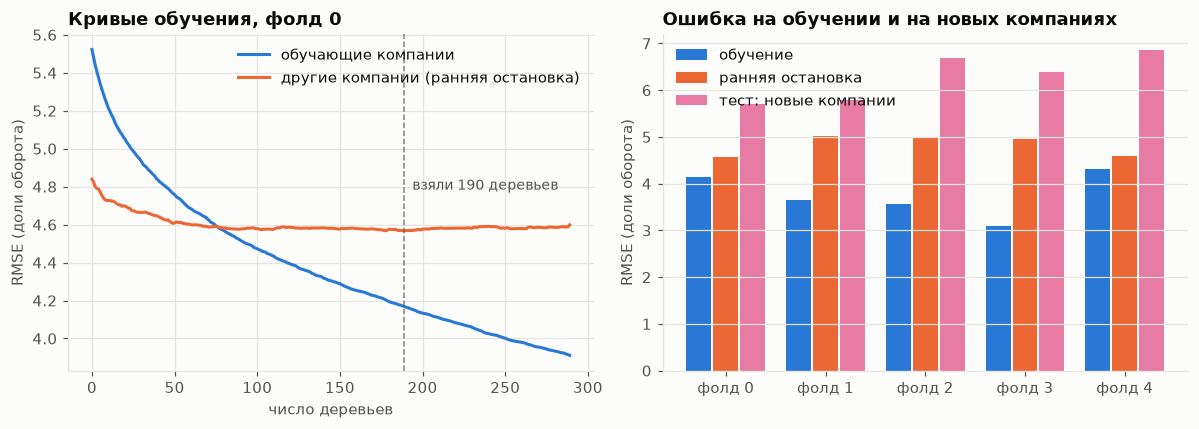

In [9]:
ratio = FOLDS["RMSE тест"] / FOLDS["RMSE обучение"]
print(f"RMSE тест / обучение по фолдам: {', '.join(f'{r:.2f}' for r in ratio)}; "
      f"разброс RMSE теста между фолдами: {FOLDS['RMSE тест'].std() / FOLDS['RMSE тест'].mean():.0%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
learn, valid = curves["learn"]["RMSE"], curves["validation"]["RMSE"]
ax1.plot(learn, color=PAL["CatBoost"], label="обучающие компании")
ax1.plot(valid, color=PAL["Гибрид"], label="другие компании (ранняя остановка)")
best_it = int(np.argmin(valid))
ax1.axvline(best_it, ls="--", lw=1, color=INK2, alpha=0.7)
ax1.text(best_it, max(valid), f"  взяли {best_it + 1} деревьев", color=INK2, fontsize=9, va="top")
ax1.set(xlabel="число деревьев", ylabel="RMSE (доли оборота)")
ax1.set_title("Кривые обучения, фолд 0")
ax1.legend(loc="upper right")
x = np.arange(len(FOLDS))
for k, (col, name) in enumerate([("RMSE обучение", "обучение"), ("RMSE ранняя остановка", "ранняя остановка"),
                                 ("RMSE тест", "тест: новые компании")]):
    ax2.bar(x + (k - 1) * 0.27, FOLDS[col], width=0.25, color=[PAL["CatBoost"], PAL["Гибрид"], PAL["Ансамбль"]][k],
            label=name)
ax2.set_xticks(x, [f"фолд {i}" for i in x])
ax2.set(ylabel="RMSE (доли оборота)")
ax2.grid(axis="x", visible=False)
ax2.set_title("Ошибка на обучении и на новых компаниях")
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Кривые обучения по итерациям
У бустинга «эпоха» это итерация, то есть одно добавленное дерево. Синяя линия показывает ошибку на обучающих
компаниях, оранжевая на других компаниях (по ним выбирается момент остановки). Чёрная точка — выбранная итерация.
Пока обе линии падают, модель учится. Когда оранжевая перестаёт падать, а синяя идёт вниз, модель начинает
запоминать обучающие компании, и обучение останавливается.

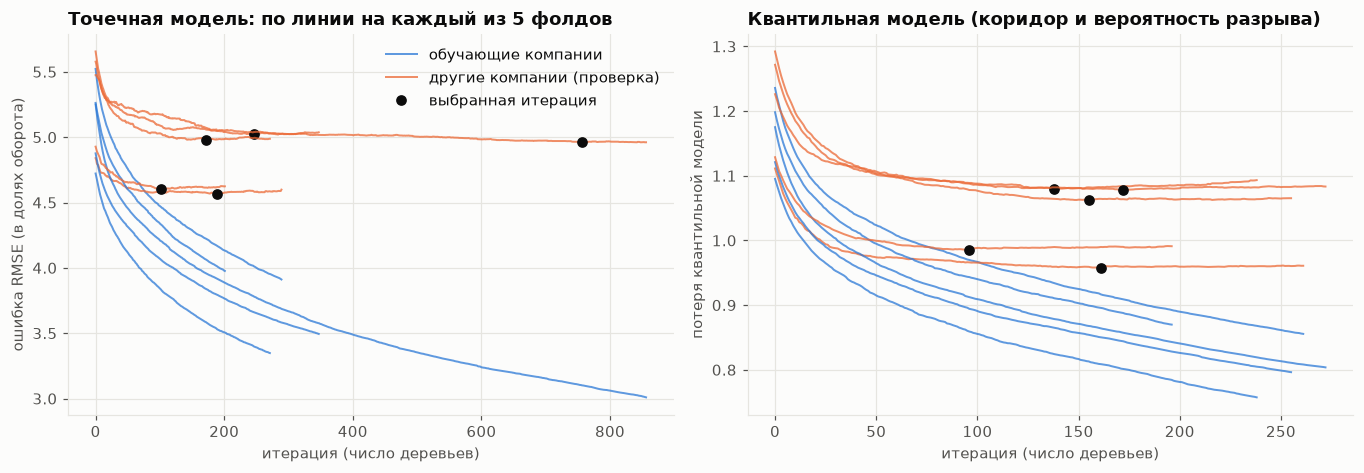

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
for k, cv in enumerate(CURVES):
    lr_, vr_ = cv["mean"]["learn"]["RMSE"], cv["mean"]["validation"]["RMSE"]
    ax1.plot(lr_, color=PAL["CatBoost"], lw=1.3, alpha=0.75, label="обучающие компании" if k == 0 else None)
    ax1.plot(vr_, color=PAL["Гибрид"], lw=1.3, alpha=0.75, label="другие компании (проверка)" if k == 0 else None)
    ax1.plot([cv["best_mean"]], [vr_[cv["best_mean"]]], "o", color=INK, ms=6, label="выбранная итерация" if k == 0 else None)
    qk_ = next(iter(cv["q"]["learn"]))
    lq_, vq_ = cv["q"]["learn"][qk_], cv["q"]["validation"][qk_]
    ax2.plot(lq_, color=PAL["CatBoost"], lw=1.3, alpha=0.75)
    ax2.plot(vq_, color=PAL["Гибрид"], lw=1.3, alpha=0.75)
    ax2.plot([cv["best_q"]], [vq_[cv["best_q"]]], "o", color=INK, ms=6)
ax1.set(xlabel="итерация (число деревьев)", ylabel="ошибка RMSE (в долях оборота)")
ax1.set_title("Точечная модель: по линии на каждый из 5 фолдов")
ax1.legend(loc="upper right")
ax2.set(xlabel="итерация (число деревьев)", ylabel="потеря квантильной модели")
ax2.set_title("Квантильная модель (коридор и вероятность разрыва)")
plt.tight_layout()
plt.show()

## 6. Задача 1: будет ли нехватка денег

Риск окна считаем как максимальную по дням вероятность того, что остаток уйдёт ниже нуля:
- у гибрида это доля вариантов Монте-Карло ниже нуля;
- у CatBoost вероятность берётся из 9 квантилей прогноза.

Тревога выдаётся, если риск выше порога. Порог подбирается на других фолдах (метрики с таким порогом отмечены звёздочкой). Для сравнения показан и порог 50%.

In [11]:
def cb_prob(q: np.ndarray, thr: float = 0.0) -> np.ndarray:
    """P(остаток < thr) по дням из квантилей.

    Внутри диапазона квантилей — линейная интерполяция функции распределения. За краями (ниже 5% и выше 95%)
    продолжаем нормальным хвостом: иначе у всех «спокойных» окон вероятность ровно 0, они сливаются в одну точку
    и ROC-кривая получает ложный прямой отрезок.
    """
    from scipy.stats import norm
    out = []
    for row in q:
        if row[0] <= thr <= row[-1]:
            out.append(np.interp(thr, row, QS))
            continue
        mid, sigma = row[QS.index(0.5)], max((row[-1] - row[0]) / (2 * norm.ppf(QS[-1])), 1e-9)
        p = norm.cdf((thr - mid) / sigma)
        out.append(min(p, QS[0]) if thr < row[0] else max(p, QS[-1]))
    return np.array(out)


W["score_CatBoost"] = [cb_prob(q).max() for q in W["cb_q"]]
W["score_Гибрид"] = [p.max() for p in W["hyb_prob"]]
# Ансамбль: модели разной природы (правила + Монте-Карло против глобального бустинга) ошибаются по-разному
W["score_Ансамбль"] = (W["score_CatBoost"] + W["score_Гибрид"]) / 2
W["ens_mean"] = [(a + b) / 2 for a, b in zip(W["cb_mean"], W["hyb_p50"])]
C = W[~W["ongoing"]].reset_index(drop=True)                     # разрыв уже идёт — не прогноз, а констатация
y = C["gap_actual"].to_numpy()
THR = CFG["gap_threshold"]
print(f"Окон для классификации: {len(C)}, из них с разрывом: {int(y.sum())} ({y.mean():.0%})")


def clf_metrics(score: np.ndarray, y_true: np.ndarray, with_proba: bool = True) -> dict:
    pred = score >= THR
    out = {"precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
           "F1": f1_score(y_true, pred)}
    if with_proba:
        out |= {"ROC-AUC": roc_auc_score(y_true, score), "PR-AUC": average_precision_score(y_true, score),
                "Brier": brier_score_loss(y_true, np.clip(score, 0, 1))}
    return out


def lead_time(df: pd.DataFrame, col: str) -> float:
    """Медиана заблаговременности (раб. дни) по найденным разрывам: сколько дней от прогноза до начала нехватки."""
    hit = df[(df[col] >= THR) & df["gap_actual"]]
    return float(hit["first_gap_wd"].median()) if len(hit) else np.nan


def bootstrap_ci(df: pd.DataFrame, col: str, metric) -> tuple[float, float]:
    """95% доверительный интервал: пересэмплируем КОМПАНИИ (окна одной компании зависимы)."""
    comp = df["company"].unique()
    groups = {c: g for c, g in df.groupby("company")}
    rs, vals = np.random.default_rng(0), []
    for _ in range(CFG["bootstrap"]):
        s = pd.concat([groups[c] for c in rs.choice(comp, size=len(comp))])
        if s["gap_actual"].nunique() == 2:
            vals.append(metric(s[col].to_numpy(), s["gap_actual"].to_numpy()))
    return tuple(np.percentile(vals, [2.5, 97.5]))


GRID_THR = np.round(np.arange(0.05, 0.96, 0.05), 2)


def cv_threshold_pred(df: pd.DataFrame, col: str) -> tuple[np.ndarray, list[float]]:
    """Порог без подглядывания: для окон фолда f берём порог, лучший по F1 на ОСТАЛЬНЫХ фолдах."""
    pred, chosen = np.zeros(len(df), dtype=bool), []
    for f in sorted(df["fold"].unique()):
        other, mine = df["fold"].ne(f), df["fold"].eq(f)
        best = max(GRID_THR, key=lambda t: f1_score(df.loc[other, "gap_actual"], df.loc[other, col] >= t))
        pred[mine.to_numpy()] = df.loc[mine, col].to_numpy() >= best
        chosen.append(float(best))
    return pred, chosen


PROB_MODELS = ("CatBoost", "Гибрид", "Ансамбль")
CV_PRED = {}
rows = []
for name in PROB_MODELS:
    col = f"score_{name}"
    mtr = clf_metrics(C[col].to_numpy(), y, with_proba=True)
    mtr |= {"заблаговременность, раб. дн.": lead_time(C, col)}
    if name in PROB_MODELS:
        pred, chosen = cv_threshold_pred(C, col)
        CV_PRED[name] = pred
        C[f"pred_{name}"] = pred.astype(float)
        mtr |= {"порог по фолдам": "/".join(f"{t:.2f}" for t in chosen),
                "precision*": precision_score(y, pred, zero_division=0), "recall*": recall_score(y, pred),
                "F1*": f1_score(y, pred)}
    rows.append({"модель": name, **mtr})
CLF = pd.DataFrame(rows).set_index("модель")
print("Без звёздочки — порог 50%; со звёздочкой (*) — порог, подобранный вложенной кросс-валидацией.")
CLF.round(3)

Окон для классификации: 1594, из них с разрывом: 268 (17%)


Без звёздочки — порог 50%; со звёздочкой (*) — порог, подобранный вложенной кросс-валидацией.


,precision,recall,F1,ROC-AUC,PR-AUC,Brier,"заблаговременность, раб. дн.",порог по фолдам,precision*,recall*,F1*
модель,,,,,,,,,,,
CatBoost,0.702,0.246,0.365,0.894,0.605,0.102,7.0,0.15/0.20/0.15/0.15/0.15,0.489,0.679,0.569
Гибрид,0.573,0.556,0.564,0.887,0.636,0.100,9.0,0.20/0.25/0.20/0.25/0.25,0.475,0.769,0.587
Ансамбль,0.701,0.437,0.538,0.902,0.662,0.089,8.0,0.25/0.35/0.25/0.25/0.25,0.528,0.679,0.594


### Матрицы ошибок
Строки показывают, что было на самом деле, столбцы что предсказала модель. Одно окно это одна компания на одну дату прогноза. Порог для каждого фолда подобран по остальным фолдам.

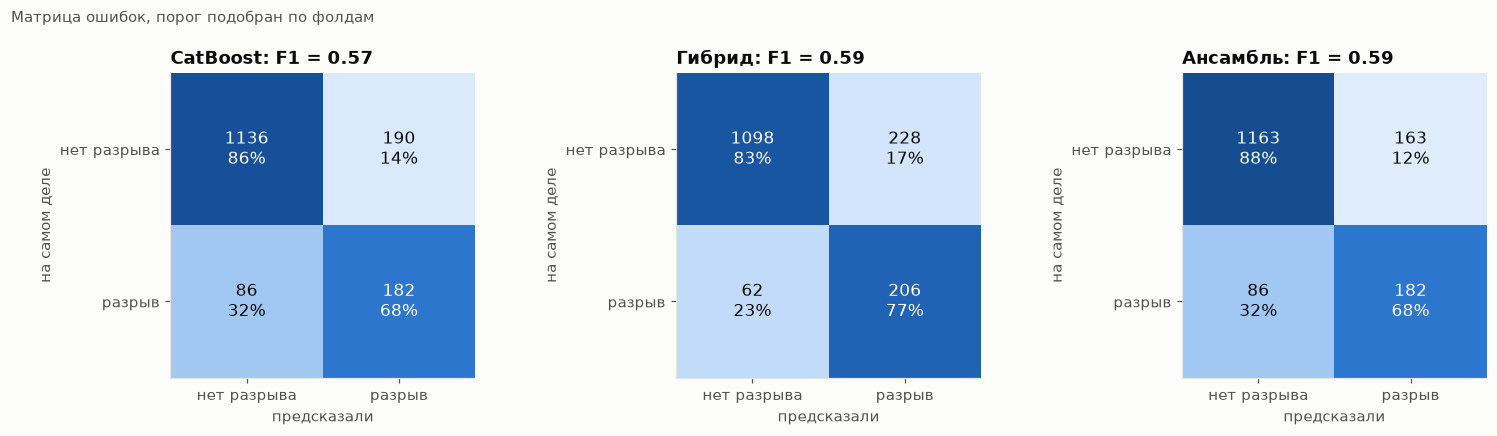

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, PROB_MODELS):
    cm = confusion_matrix(y, CV_PRED[name], labels=[False, True])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=11,
                color="white" if share[i, j] > 0.55 else INK)
    ax.set_xticks([0, 1], ["нет разрыва", "разрыв"])
    ax.set_yticks([0, 1], ["нет разрыва", "разрыв"])
    ax.set_xlabel("предсказали")
    ax.set_ylabel("на самом деле")
    ax.grid(False)
    ax.set_title(f"{name}: F1 = {CLF.loc[name, 'F1*']:.2f}")
fig.suptitle("Матрица ошибок, порог подобран по фолдам", x=0.01, ha="left", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

### ROC- и PR-кривые
ROC-AUC показывает, насколько хорошо модель ставит окна с разрывом выше окон без разрыва. Разрывов мало, поэтому рядом PR-кривая: при редком событии она точнее. Пунктир на ней это доля разрывов, то есть уровень случайной модели.

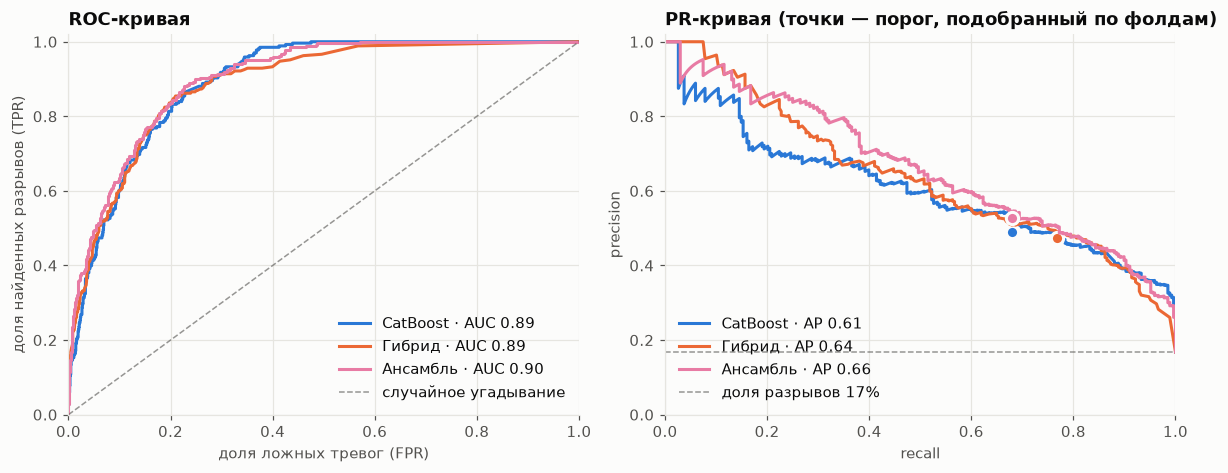

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
for name in PROB_MODELS:
    s = C[f"score_{name}"].to_numpy()
    fpr, tpr, _ = roc_curve(y, s)
    ax1.plot(fpr, tpr, color=PAL[name], label=f"{name} · AUC {roc_auc_score(y, s):.2f}")
    pr, rc, _ = precision_recall_curve(y, s)
    ax2.plot(rc, pr, color=PAL[name], label=f"{name} · AP {average_precision_score(y, s):.2f}")
    p_at = CV_PRED[name]
    ax2.plot([recall_score(y, p_at)], [precision_score(y, p_at, zero_division=0)], "o", ms=8, color=PAL[name],
             markeredgecolor=SURF, markeredgewidth=2)
ax1.plot([0, 1], [0, 1], ls="--", lw=1, color=INK2, alpha=0.6, label="случайное угадывание")
ax1.set(xlabel="доля ложных тревог (FPR)", ylabel="доля найденных разрывов (TPR)", xlim=(0, 1), ylim=(0, 1.02))
ax1.set_title("ROC-кривая")
ax1.legend(loc="lower right")
ax2.axhline(y.mean(), ls="--", lw=1, color=INK2, alpha=0.6, label=f"доля разрывов {y.mean():.0%}")
ax2.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02))
ax2.set_title("PR-кривая (точки — порог, подобранный по фолдам)")
ax2.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Калибровка и выбор порога
Слева: если модель говорит 70%, сбывается ли это примерно в 70% случаев. Справа: F1 при разных порогах, точка отмечает максимум.

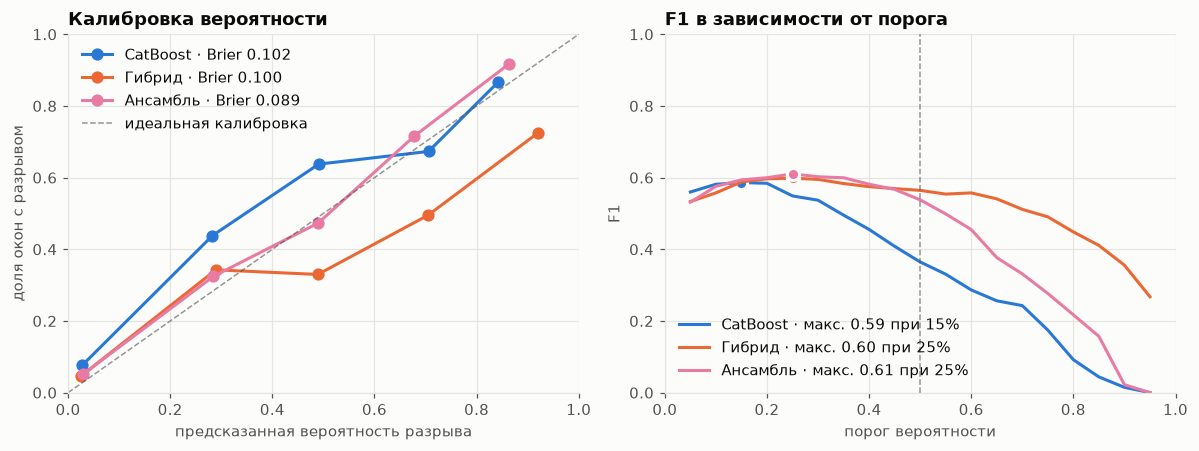

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.linspace(0, 1, 6)
for name in PROB_MODELS:
    s = C[f"score_{name}"].to_numpy()
    idx = np.clip(np.digitize(s, bins) - 1, 0, len(bins) - 2)
    cal = pd.DataFrame({"b": idx, "s": s, "y": y}).groupby("b").agg(s=("s", "mean"), y=("y", "mean"), n=("y", "size"))
    cal = cal[cal["n"] >= 5]
    ax1.plot(cal["s"], cal["y"], "-o", ms=7, color=PAL[name], label=f"{name} · Brier {brier_score_loss(y, s):.3f}")
    thr = np.linspace(0.05, 0.95, 19)
    f1s = [f1_score(y, s >= t) for t in thr]
    best = int(np.argmax(f1s))
    ax2.plot(thr, f1s, color=PAL[name], label=f"{name} · макс. {f1s[best]:.2f} при {thr[best]:.0%}")
    ax2.plot([thr[best]], [f1s[best]], "o", ms=8, color=PAL[name], markeredgecolor=SURF, markeredgewidth=2)
ax1.plot([0, 1], [0, 1], ls="--", lw=1, color=INK2, alpha=0.6, label="идеальная калибровка")
ax1.set(xlabel="предсказанная вероятность разрыва", ylabel="доля окон с разрывом", xlim=(0, 1), ylim=(0, 1))
ax1.set_title("Калибровка вероятности")
ax1.legend(loc="upper left")
ax2.axvline(THR, ls="--", lw=1, color=INK2, alpha=0.6)
ax2.set(xlabel="порог вероятности", ylabel="F1", xlim=(0, 1), ylim=(0, 1))
ax2.set_title("F1 в зависимости от порога")
ax2.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 7. Задача 2: остаток через h дней

Ошибку делим на средний дневной расход компании: «ошибка 3» значит, что промахнулись на три дня обычных трат. Так можно сравнивать маленькую и большую компанию. Сравниваем с остатком без денег владельца, потому что именно его прогнозируют модели.

In [15]:
HS = [5, 10, 20, 30]
PRED = {"CatBoost": "cb_mean", "Гибрид": "hyb_p50", "Ансамбль": "ens_mean"}


def err(df: pd.DataFrame, col: str, h: int) -> np.ndarray:
    return np.array([(p[h - 1] - a[h - 1]) / s for p, a, s in zip(df[col], df["actual_oper"], df["scale"])])


reg = []
for name, col in PRED.items():
    row = {"модель": name}
    for h in HS:
        e = err(W, col, h)
        row[f"RMSE h{h}"] = np.sqrt(np.mean(e ** 2))
        row[f"MAE h{h}"] = np.mean(np.abs(e))
    row["смещение h30"] = np.mean(err(W, col, 30))
    reg.append(row)
REG = pd.DataFrame(reg).set_index("модель")


def coverage_and_pinball(lo_col, mid_col, hi_col, df) -> tuple[float, float]:
    cov, pin = [], []
    for lo, mid, hi, a, s in zip(df[lo_col], df[mid_col], df[hi_col], df["actual_oper"], df["scale"]):
        cov.append(np.mean((a >= lo) & (a <= hi)))
        for q, p in ((0.1, lo), (0.5, mid), (0.9, hi)):
            d = (a - p) / s
            pin.append(np.mean(np.maximum(q * d, (q - 1) * d)))
    return float(np.mean(cov)), float(np.mean(pin))


i10, i50, i90 = QS.index(0.1), QS.index(0.5), QS.index(0.9)
W["cb_p10"], W["cb_p50"], W["cb_p90"] = ([q[:, i] for q in W["cb_q"]] for i in (i10, i50, i90))
REG.loc["CatBoost", ["покрытие P10–P90", "pinball"]] = coverage_and_pinball("cb_p10", "cb_p50", "cb_p90", W)
REG.loc["Гибрид", ["покрытие P10–P90", "pinball"]] = coverage_and_pinball("hyb_p10", "hyb_p50", "hyb_p90", W)
# Коридор ансамбля: среднее коридоров гибрида и CatBoost (по каждому дню отдельно для P10, P50 и P90)
for q_ in ("p10", "p50", "p90"):
    W[f"ens_{q_}"] = [(a + b) / 2 for a, b in zip(W[f"cb_{q_}"], W[f"hyb_{q_}"])]
REG.loc["Ансамбль", ["покрытие P10–P90", "pinball"]] = coverage_and_pinball("ens_p10", "ens_p50", "ens_p90", W)
REG.round(2)

,RMSE h5,MAE h5,RMSE h10,MAE h10,RMSE h20,MAE h20,RMSE h30,MAE h30,смещение h30,покрытие P10–P90,pinball
модель,,,,,,,,,,,
CatBoost,6.66,3.35,9.83,4.86,15.23,7.31,21.46,9.62,-1.20,0.72,2.12
Гибрид,6.60,3.25,9.84,4.71,14.98,7.11,21.90,9.93,-1.74,0.73,2.06
Ансамбль,6.46,3.10,9.61,4.50,14.80,6.79,21.32,9.20,-1.47,0.77,1.97


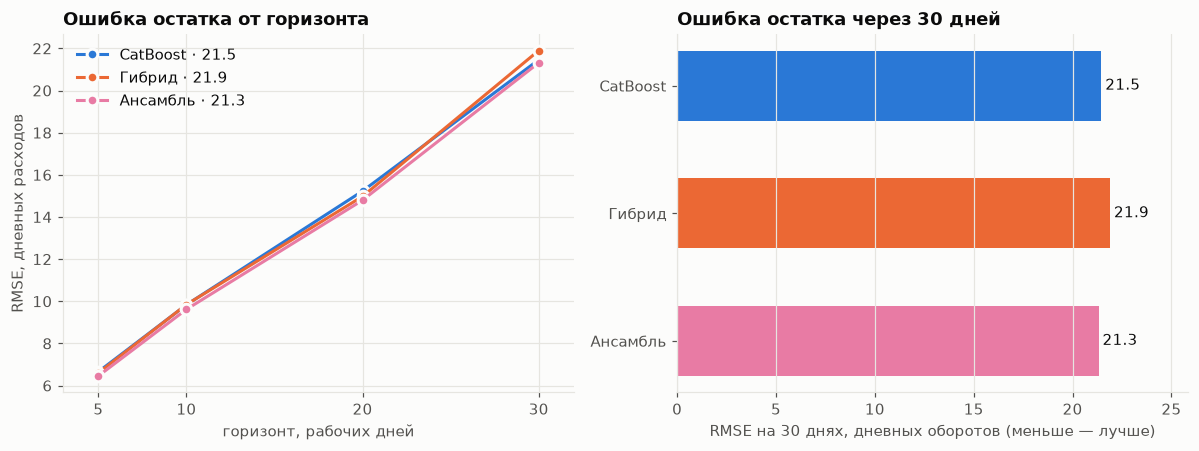

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for name in PRED:
    r = [REG.loc[name, f"RMSE h{h}"] for h in HS]
    ax1.plot(HS, r, "-o", ms=7, color=PAL[name], label=f"{name} · {r[-1]:.1f}", markeredgecolor=SURF, markeredgewidth=2)
ax1.set(xlabel="горизонт, рабочих дней", ylabel="RMSE, дневных расходов", xticks=HS, xlim=(3, 32))
ax1.set_title("Ошибка остатка от горизонта")
ax1.legend(loc="upper left")
names = list(PRED)
vals = [REG.loc[n, "RMSE h30"] for n in names]
bars = ax2.barh(names[::-1], vals[::-1], color=[PAL[n] for n in names[::-1]], height=0.55)
for b, v in zip(bars, vals[::-1]):
    ax2.text(v + 0.2, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", color=INK)
ax2.set(xlabel="RMSE на 30 днях, дневных оборотов (меньше — лучше)", xlim=(0, max(vals) * 1.18))
ax2.grid(axis="y", visible=False)
ax2.set_title("Ошибка остатка через 30 дней")
plt.tight_layout()
plt.show()

### Предсказание против факта
Слева: каждая точка это одно окно. По горизонтали на сколько CatBoost предсказал изменение остатка за 30 дней,
по вертикали на сколько он изменился на самом деле (в дневных оборотах компании). Идеальный прогноз лежит на
пунктирной диагонали. Справа: распределение ошибок прогноза остатка на 30 дней у трёх подходов; чем уже и
симметричнее горка около нуля, тем лучше.

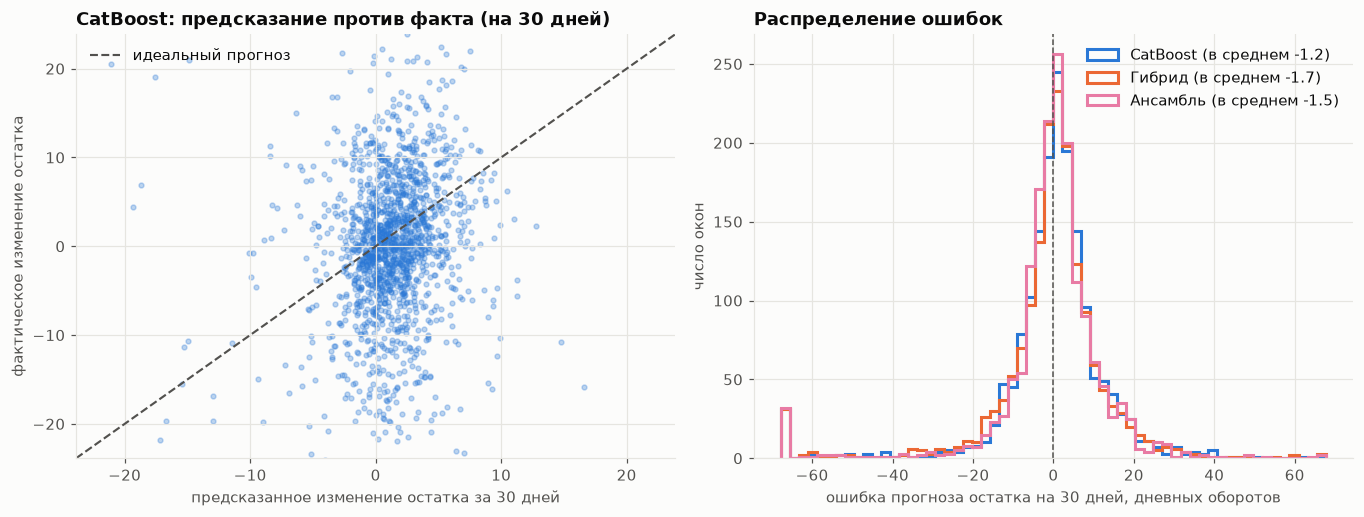

In [17]:
h30_ = 30
pred_ = np.array([(p_[h30_ - 1] - b_) / s_ for p_, b_, s_ in zip(W["cb_mean"], W["bal0"], W["scale"])])
act_ = np.array([(a_[h30_ - 1] - b_) / s_ for a_, b_, s_ in zip(W["actual_oper"], W["bal0"], W["scale"])])
lim_ = float(np.percentile(np.abs(np.r_[pred_, act_]), 97))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax1.scatter(pred_, act_, s=10, alpha=0.3, color=PAL["CatBoost"])
ax1.plot([-lim_, lim_], [-lim_, lim_], "--", color=INK2, lw=1.4, label="идеальный прогноз")
ax1.set(xlim=(-lim_, lim_), ylim=(-lim_, lim_), xlabel="предсказанное изменение остатка за 30 дней", ylabel="фактическое изменение остатка")
ax1.set_title("CatBoost: предсказание против факта (на 30 дней)")
ax1.legend(loc="upper left")
errs_ = {n_: err(W, c_, 30) for n_, c_ in PRED.items()}
lim2_ = float(np.percentile(np.abs(np.concatenate(list(errs_.values()))), 98))
for n_, e_ in errs_.items():
    ax2.hist(np.clip(e_, -lim2_, lim2_), bins=60, histtype="step", lw=2, color=PAL[n_], label=f"{n_} (в среднем {np.mean(e_):+.1f})")
ax2.axvline(0, color=INK2, lw=1, ls="--")
ax2.set(xlabel="ошибка прогноза остатка на 30 дней, дневных оборотов", ylabel="число окон")
ax2.set_title("Распределение ошибок")
ax2.legend()
plt.tight_layout()
plt.show()

### Стабильность по фолдам
Качество поиска разрывов отдельно на каждой из пяти групп компаний. Если точки лежат близко, результат стабилен
и не зависит от того, какие компании попали в тест.

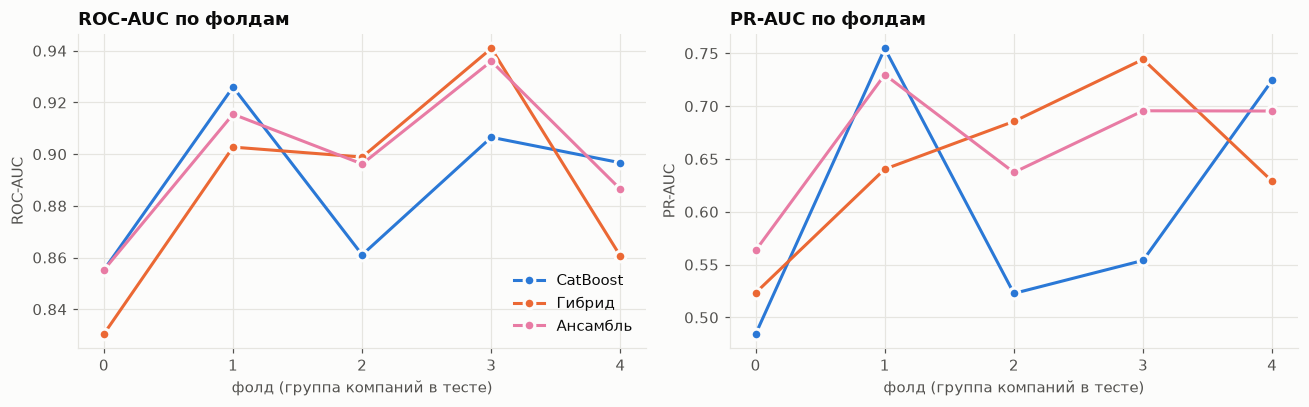

модель,CatBoost,Ансамбль,Гибрид
фолд,,,
0,0.855,0.855,0.830
1,0.926,0.915,0.903
2,0.861,0.896,0.899
3,0.907,0.936,0.941
4,0.897,0.886,0.861


In [18]:
fold_rows_ = []
for f_ in sorted(C["fold"].unique()):
    sub_ = C[C["fold"] == f_]
    if sub_["gap_actual"].nunique() == 2:
        for n_ in PROB_MODELS:
            fold_rows_.append({"фолд": int(f_), "модель": n_, "ROC-AUC": roc_auc_score(sub_["gap_actual"], sub_[f"score_{n_}"]),
                               "PR-AUC": average_precision_score(sub_["gap_actual"], sub_[f"score_{n_}"])})
FOLD_METRICS = pd.DataFrame(fold_rows_)
fig, axes_ = plt.subplots(1, 2, figsize=(12, 3.8))
for ax_, met_ in zip(axes_, ("ROC-AUC", "PR-AUC")):
    for n_ in PROB_MODELS:
        d_ = FOLD_METRICS[FOLD_METRICS["модель"] == n_]
        ax_.plot(d_["фолд"], d_[met_], "-o", color=PAL[n_], lw=2, ms=7, label=n_, markeredgecolor=SURF, markeredgewidth=2)
    ax_.set(xlabel="фолд (группа компаний в тесте)", ylabel=met_, xticks=sorted(C["fold"].unique().astype(int)))
    ax_.set_title(f"{met_} по фолдам")
axes_[0].legend()
plt.tight_layout()
plt.show()
FOLD_METRICS.pivot(index="фолд", columns="модель", values="ROC-AUC").round(3)

### Пример: одна компания с разрывом
Факт, прогноз CatBoost с коридором P10–P90 и прогноз гибрида от одной даты. Взято окно с разрывом, где CatBoost дал самый высокий риск. Это пример, а не оценка качества: качество показывают таблицы выше.

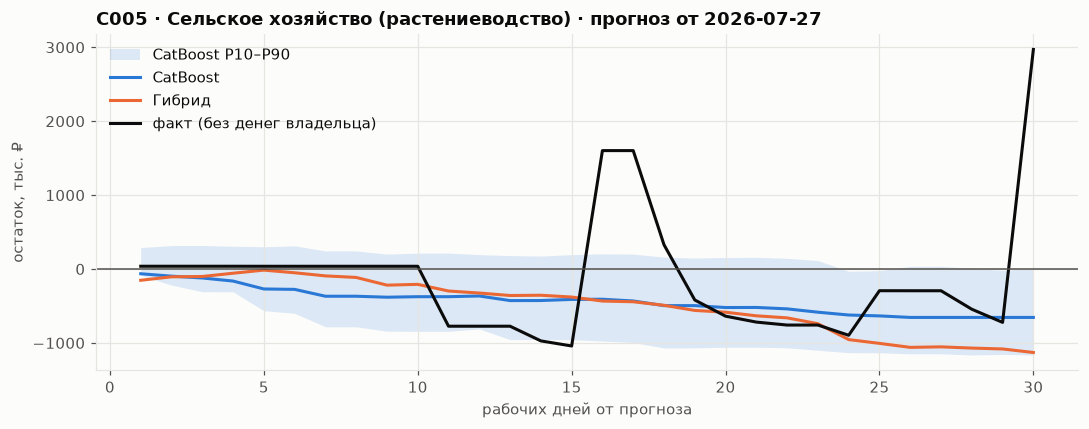

In [19]:
ex = C[C["gap_actual"]].sort_values("score_CatBoost", ascending=False).iloc[0]
ex = W[(W["company"].eq(ex["company"])) & (W["pos"].eq(ex["pos"]))].iloc[0]
d = np.arange(1, H + 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(d, ex["cb_p10"] / 1e3, ex["cb_p90"] / 1e3, color=PAL["CatBoost"], alpha=0.15, lw=0, label="CatBoost P10–P90")
ax.plot(d, ex["cb_mean"] / 1e3, color=PAL["CatBoost"], label="CatBoost")
ax.plot(d, ex["hyb_p50"] / 1e3, color=PAL["Гибрид"], label="Гибрид")
ax.plot(d, ex["actual_oper"] / 1e3, color=INK, lw=2, label="факт (без денег владельца)")
ax.axhline(0, color=INK2, lw=1)
ax.set(xlabel="рабочих дней от прогноза", ylabel="остаток, тыс. ₽")
ax.set_title(f"{ex['company']} · {ex['industry']} · прогноз от {ex['cutoff'].date()}")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

### Какие признаки важнее всего для CatBoost
Средняя важность признаков по фолдам (модель RMSE).

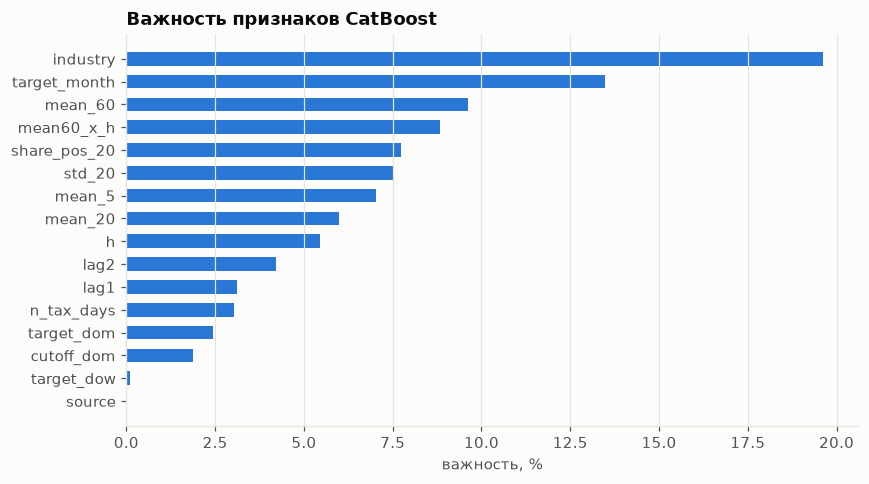

In [20]:
imp = pd.concat(importances, axis=1).mean(axis=1).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values, color=PAL["CatBoost"], height=0.6)
ax.grid(axis="y", visible=False)
ax.set(xlabel="важность, %")
ax.set_title("Важность признаков CatBoost")
plt.tight_layout()
plt.show()

## 8. Задача 3: категоризация операций

Три слоя: правила по назначению платежа, история контрагента, ML (TF-IDF по символам + логистическая регрессия). Правила покрывают 99,99% операций, но в новых данных формулировки могут быть другими, и тогда работает ML. Его и проверяем:
- учим на одних компаниях, проверяем на других;
- правильным ответом считаем разметку по правилам (ручная разметка 500 операций пока не сделана, поэтому это проверка устойчивости, а не итоговая точность);
- отдельно проверяем на искажённых назначениях: опечатки, сокращения, выпавшие слова.

In [21]:
lab = pd.concat([p.ops.assign(company=c) for c, p in preps.items()], ignore_index=True)
lab = lab[lab["category_source"].eq("rule") & lab["category"].ne("other") & lab["payment_purpose"].ne("")]
test_c = set(ids[[fold_of[c] == 0 for c in ids]])
tr_l, te_l = lab[~lab["company"].isin(test_c)], lab[lab["company"].isin(test_c)]
tr_l = tr_l.sample(frac=1.0, random_state=0).groupby("category").head(3000)     # как в приложении: баланс классов
te_l = te_l.sample(frac=1.0, random_state=0).groupby("category").head(400)


def corrupt(text: str, rs: np.random.Generator) -> str:
    words = text.split()
    if len(words) > 3:                                                   # выпало одно слово
        words.pop(rs.integers(len(words)))
    out = []
    for wd in words:
        if len(wd) > 5 and rs.random() < 0.3:                            # сокращение: «поставку» → «пост.»
            wd = wd[: rs.integers(3, 5)] + "."
        elif len(wd) > 3 and rs.random() < 0.3:                          # опечатка: две буквы поменялись местами
            k = rs.integers(len(wd) - 1)
            wd = wd[:k] + wd[k + 1] + wd[k] + wd[k + 2:]
        out.append(wd)
    return " ".join(out).lower()


rs = np.random.default_rng(1)
clf = TextClassifier().fit(tr_l["direction"] + " " + tr_l["payment_purpose"], tr_l["category"])
text_clean = te_l["direction"] + " " + te_l["payment_purpose"]
text_noisy = te_l["direction"] + " " + te_l["payment_purpose"].map(lambda s: corrupt(s, rs))
print("Пример искажения:", te_l["payment_purpose"].iloc[0], "→", corrupt(te_l["payment_purpose"].iloc[0], rs))

cat_rows = []
for name, text in (("чистые назначения", text_clean), ("искажённые назначения", text_noisy)):
    pred, _ = clf.predict(text)
    proba = clf.pipeline.predict_proba(text)
    cat_rows.append({"проверка": name, "accuracy": accuracy_score(te_l["category"], pred),
                     "macro-F1": f1_score(te_l["category"], pred, average="macro"),
                     "ROC-AUC (one-vs-rest, macro)": roc_auc_score(te_l["category"], proba, multi_class="ovr",
                                                                    labels=clf.pipeline.classes_)})
    if name == "искажённые назначения":
        noisy_pred = pred
CAT = pd.DataFrame(cat_rows).set_index("проверка")
print(f"Операций в проверке: {len(te_l):,}, категорий: {te_l['category'].nunique()}")
CAT.round(3)

Пример искажения: Оплата по договору № 339/19 по счету 1198 от 16.02.2026 за поставку товара. НДС не облагается. → оплата по дог. № 339/19 по счету 1198 от 16.02.2026 за поставку ндс не облагается.


Операций в проверке: 7,315, категорий: 27


,accuracy,macro-F1,"ROC-AUC (one-vs-rest, macro)"
проверка,,,
чистые назначения,1.000,1.000,1.0
искажённые назначения,0.946,0.948,1.0


In [22]:
print(classification_report(te_l["category"], noisy_pred, digits=2, zero_division=0))

                  precision    recall  f1-score   support

       acquiring       1.00      1.00      1.00       400
       bank_fees       1.00      0.95      0.98       400
           capex       1.00      0.79      0.88       135
            cash       1.00      0.89      0.94       400
  client_payment       0.81      1.00      0.90       400
     enforcement       1.00      0.86      0.92         7
        facility       1.00      0.84      0.91       400
             gph       0.99      1.00      1.00       400
   it_accounting       0.99      0.95      0.97       400
         leasing       1.00      0.96      0.98        89
         loan_in       1.00      1.00      1.00         2
    loan_payment       1.00      0.96      0.98        89
       logistics       0.97      0.84      0.90       400
       marketing       1.00      0.95      0.98       400
     marketplace       1.00      0.93      0.96       400
 own_transfer_in       1.00      0.95      0.98        43
own_transfer_

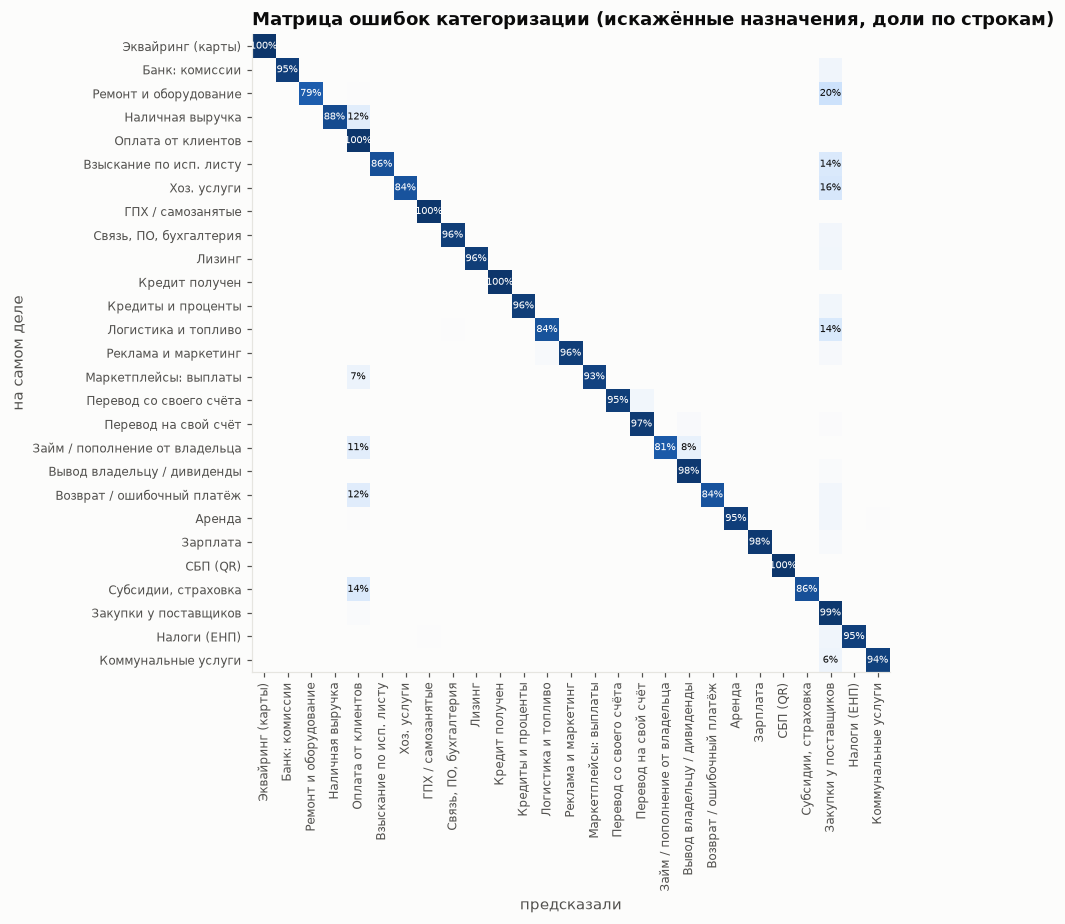

In [23]:
classes = sorted(te_l["category"].unique())
cm = confusion_matrix(te_l["category"], noisy_pred, labels=classes)
share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(10, 8.5))
ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(share):
    if v >= 0.05:
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6.5, color="white" if v > 0.55 else INK)
names_ru = [CATEGORIES[c].label if c in CATEGORIES else c for c in classes]
ax.set_xticks(range(len(classes)), names_ru, rotation=90, fontsize=8)
ax.set_yticks(range(len(classes)), names_ru, fontsize=8)
ax.set(xlabel="предсказали", ylabel="на самом деле")
ax.grid(False)
ax.set_title("Матрица ошибок категоризации (искажённые назначения, доли по строкам)")
plt.tight_layout()
plt.show()

### Качество по категориям, кривая обучения и уверенность модели
Слева: F1 по каждой категории (красные ниже 0,8). Посередине: как растёт качество, когда модели дают больше примеров
для обучения (если кривая вышла на плато, новые данные почти ничего не добавят). Справа: насколько модель уверена
в верных и неверных ответах; хорошо, когда ошибки сосредоточены в области низкой уверенности.

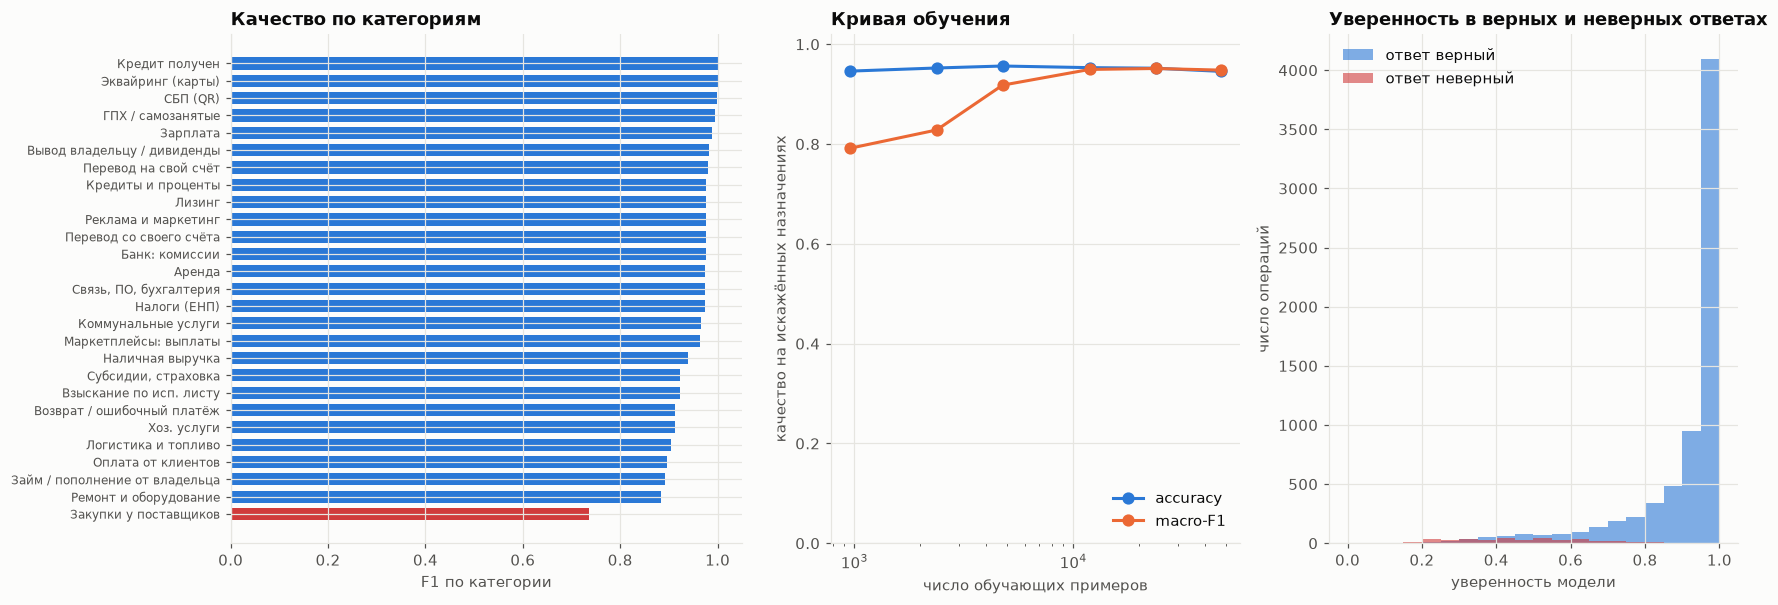

,примеров,accuracy,macro-F1
0,951,0.946,0.791
1,2378,0.952,0.828
2,4756,0.956,0.918
3,11891,0.953,0.950
4,23782,0.952,0.951
5,47565,0.946,0.948


In [24]:
rep_ = classification_report(te_l["category"], noisy_pred, output_dict=True, zero_division=0)
per_ = pd.DataFrame({c_: rep_[c_] for c_ in classes}).T
per_.index = [CATEGORIES[c_].label if c_ in CATEGORIES else c_ for c_ in per_.index]
per_ = per_.sort_values("f1-score")
sizes_ = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]
lc_rows = []
for frac_ in sizes_:
    sub_ = tr_l.sample(frac=frac_, random_state=0) if frac_ < 1 else tr_l
    c_ = TextClassifier().fit(sub_["direction"] + " " + sub_["payment_purpose"], sub_["category"])
    pr_, _ = c_.predict(text_noisy)
    lc_rows.append({"примеров": len(sub_), "accuracy": accuracy_score(te_l["category"], pr_),
                    "macro-F1": f1_score(te_l["category"], pr_, average="macro")})
LC = pd.DataFrame(lc_rows)
fig, axes_ = plt.subplots(1, 3, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.25, 1, 1]})
axes_[0].barh(per_.index, per_["f1-score"], color=["#d03b3b" if v_ < 0.8 else PAL["CatBoost"] for v_ in per_["f1-score"]], height=0.7)
axes_[0].set(xlim=(0, 1.05), xlabel="F1 по категории")
axes_[0].set_title("Качество по категориям")
axes_[0].tick_params(axis="y", labelsize=8)
axes_[1].plot(LC["примеров"], LC["accuracy"], "-o", color=PAL["CatBoost"], lw=2, ms=7, label="accuracy")
axes_[1].plot(LC["примеров"], LC["macro-F1"], "-o", color=PAL["Гибрид"], lw=2, ms=7, label="macro-F1")
axes_[1].set(xscale="log", xlabel="число обучающих примеров", ylabel="качество на искажённых назначениях", ylim=(0, 1.02))
axes_[1].set_title("Кривая обучения")
axes_[1].legend(loc="lower right")
conf_, ok_ = proba.max(axis=1), (np.asarray(noisy_pred) == te_l["category"].to_numpy())
axes_[2].hist(conf_[ok_], bins=20, range=(0, 1), color=PAL["CatBoost"], alpha=0.6, label="ответ верный")
axes_[2].hist(conf_[~ok_], bins=20, range=(0, 1), color="#d03b3b", alpha=0.6, label="ответ неверный")
axes_[2].set(xlabel="уверенность модели", ylabel="число операций")
axes_[2].set_title("Уверенность в верных и неверных ответах")
axes_[2].legend()
plt.tight_layout()
plt.show()
LC.round(3)

## 9. Розничная выручка: CatBoost против слоя розницы гибрида

Розница это эквайринг, СБП, наличные и выплаты маркетплейсов. Сравниваем два способа прогнозировать накопленную
выручку за h рабочих дней на компаниях, где розница больше 5% поступлений:
- **слой розницы гибрида**: ожидаемая выручка по каждому дню недели;
- **CatBoost**, обученный на других компаниях (те же 5 групп, что выше).

Ошибка считается в дневных оборотах компании, чем меньше, тем лучше.

In [25]:
from app.domain.calendar import working_days_after
from app.domain.categories import RETAIL

r_flows, r_gaps = {}, {}
for cid, prep_ in preps.items():
    good_ = prep_.ops[prep_.ops["quality"].isin(["ok", "after_gap"])]
    days_ = pd.DatetimeIndex(prep_.panel["date"])
    b_ = good_[good_["category"].isin(RETAIL)].groupby("operation_date")["signed"].sum().reindex(days_, fill_value=0.0)
    inflow_ = good_.loc[good_["direction"].eq("in"), "amount"].sum()
    if inflow_ and b_.clip(lower=0).sum() / inflow_ >= 0.05:
        r_flows[cid], r_gaps[cid] = b_, prep_.panel["after_gap"].to_numpy()
r_ids = sorted(r_flows)
r_eval = {c: eval_positions(preps[c]) for c in r_ids}
print(f"Компаний с розницей: {len(r_ids)} из {len(preps)}")


def retail_rows(cids, positions=False) -> pd.DataFrame:
    frames = []
    for c in cids:
        kw = {"positions": r_eval[c]} if positions else {"horizons": CFG["train_horizons"], "max_target_date": EVAL_START}
        r = make_cum_rows(r_flows[c], INDUSTRY.get(c, "unknown"), step=CFG["train_step"], min_history=CFG["min_history"],
                          after_gap=r_gaps[c], company=c, **kw)
        if len(r):
            frames.append(r)
    return pd.concat(frames, ignore_index=True)


def hybrid_retail(rows: pd.DataFrame) -> np.ndarray:
    """Накопленная выручка по слою розницы гибрида в тех же единицах, что цель (в долях масштаба строки)."""
    out, cache = np.zeros(len(rows)), {}
    for i, (c, cutoff, h, sc) in enumerate(zip(rows["company"], rows["cutoff"], rows["h"], rows["scale"])):
        if (c, cutoff) not in cache:
            prep_ = preps[c]
            m_ = fit(prep_.ops[prep_.ops["operation_date"].le(cutoff)], prep_.panel[prep_.panel["date"].le(cutoff)])
            dows_ = np.array([d.weekday() for d in working_days_after(cutoff.date(), H)])
            cache[(c, cutoff)] = np.cumsum(m_.revenue_dow[dows_])
        out[i] = cache[(c, cutoff)][h - 1] / sc
    return out


RET_H = [5, 10, 20, 30]
parts, rng_r = [], np.random.default_rng(CFG["seed"])
for f in range(CFG["n_folds"]):
    tr_ids = [c for c in r_ids if fold_of[c] != f]
    v_ids = set(rng_r.choice(tr_ids, size=max(2, int(len(tr_ids) * CFG["val_frac"])), replace=False))
    allr = retail_rows(tr_ids)
    tr_, va_ = allr[~allr["company"].isin(v_ids)], allr[allr["company"].isin(v_ids)]
    lo_, hi_ = tr_["y"].quantile([0.005, 0.995])
    tr_, va_ = tr_.assign(y=tr_["y"].clip(lo_, hi_)), va_.assign(y=va_["y"].clip(lo_, hi_))
    model_r = fit_cb("RMSE", tr_, va_)
    te_ = retail_rows([c for c in r_ids if fold_of[c] == f], positions=True)
    te_ = te_[te_["h"].isin(RET_H)]
    parts.append(te_.assign(hybrid=hybrid_retail(te_), catboost=model_r.predict(X(te_, True)))[["company", "h", "y", "hybrid", "catboost"]])
RET = pd.concat(parts, ignore_index=True)
rmse_r = lambda d, c: float(np.sqrt(np.mean((d[c] - d["y"]) ** 2)))  # noqa: E731
RET_TABLE = pd.DataFrame({f"{h} дн.": {"Слой розницы гибрида": rmse_r(RET[RET["h"].eq(h)], "hybrid"),
                                       "CatBoost": rmse_r(RET[RET["h"].eq(h)], "catboost")} for h in RET_H}).T
RET_TABLE["CatBoost точнее в"] = RET_TABLE["Слой розницы гибрида"] / RET_TABLE["CatBoost"]
RET_TABLE.round(2).rename_axis("горизонт")

Компаний с розницей: 88 из 150


,Слой розницы гибрида,CatBoost,CatBoost точнее в
горизонт,,,
5 дн.,1.42,1.25,1.13
10 дн.,2.79,2.08,1.34
20 дн.,6.16,4.85,1.27
30 дн.,9.74,7.73,1.26


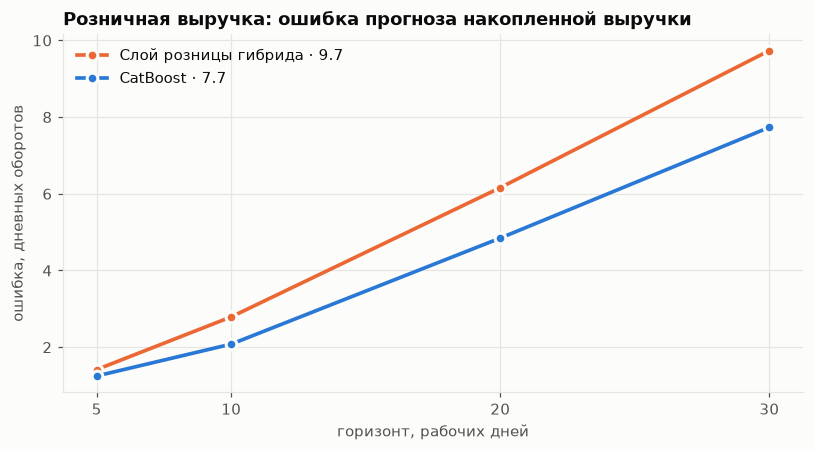

На 30 днях ошибка CatBoost 7.7, у слоя розницы гибрида 9.7: в 1.3 раза меньше.


In [26]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name_, col_, color_ in (("Слой розницы гибрида", "hybrid", PAL["Гибрид"]), ("CatBoost", "catboost", PAL["CatBoost"])):
    vals_ = [rmse_r(RET[RET["h"].eq(h)], col_) for h in RET_H]
    ax.plot(RET_H, vals_, "-o", ms=7, lw=2.4, color=color_, label=f"{name_} · {vals_[-1]:.1f}", markeredgecolor=SURF, markeredgewidth=2)
ax.set(xlabel="горизонт, рабочих дней", ylabel="ошибка, дневных оборотов", xticks=RET_H)
ax.set_title("Розничная выручка: ошибка прогноза накопленной выручки")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
RET_30 = (rmse_r(RET[RET["h"].eq(30)], "hybrid"), rmse_r(RET[RET["h"].eq(30)], "catboost"))
print(f"На 30 днях ошибка CatBoost {RET_30[1]:.1f}, у слоя розницы гибрида {RET_30[0]:.1f}: в {RET_30[0] / RET_30[1]:.1f} раза меньше.")

## 10. Сводка

In [27]:
summary = pd.DataFrame({
    "F1 (порог 50%)": CLF["F1"], "F1 (порог по фолдам)": CLF.get("F1*"), "ROC-AUC": CLF.get("ROC-AUC"),
    "PR-AUC": CLF.get("PR-AUC"), "RMSE h30": REG["RMSE h30"],
}).loc[["CatBoost", "Гибрид", "Ансамбль"]]
summary.round(2)

,F1 (порог 50%),F1 (порог по фолдам),ROC-AUC,PR-AUC,RMSE h30
модель,,,,,
CatBoost,0.36,0.57,0.89,0.61,21.46
Гибрид,0.56,0.59,0.89,0.64,21.90
Ансамбль,0.54,0.59,0.90,0.66,21.32


## 11. Какую модель выбрали

Для поиска разрывов выбрали ансамбль гибрида и CatBoost: у него лучшие ROC-AUC, PR-AUC и Brier из трёх вариантов
(таблица в разделе 6), а F1 не хуже. Итог по каждой задаче в таблице ниже.

In [28]:
BEST = max(PROB_MODELS, key=lambda n: CLF.loc[n, "PR-AUC"])
print(f"Для поиска разрывов выбрана модель: {BEST}")

Для поиска разрывов выбрана модель: Ансамбль


### Итоговый выбор по задачам

In [29]:
rows = [
    {"задача": "Поиск кассовых разрывов", "выбрано": BEST,
     "ROC-AUC": CLF.loc[BEST, "ROC-AUC"], "PR-AUC": CLF.loc[BEST, "PR-AUC"], "F1 (порог по фолдам)": CLF.loc[BEST, "F1*"],
     "Brier": CLF.loc[BEST, "Brier"], "почему": "лучший PR-AUC и Brier, не хуже одиночных моделей"},
    {"задача": "Остаток через 30 дней", "выбрано": "Ансамбль",
     "ROC-AUC": None, "PR-AUC": None, "F1 (порог по фолдам)": None, "Brier": None,
     "почему": "ошибка около 21 дневного оборота у всех моделей, различия внутри погрешности"},
    {"задача": "Розничная выручка", "выбрано": "CatBoost",
     "ROC-AUC": None, "PR-AUC": None, "F1 (порог по фолдам)": None, "Brier": None,
     "почему": f"ошибка на 30 днях {RET_30[1]:.1f} против {RET_30[0]:.1f} у слоя розницы гибрида (раздел 9)"},
    {"задача": "Категория операции", "выбрано": "TF-IDF + логистическая регрессия",
     "ROC-AUC": float(CAT.loc["искажённые назначения", "ROC-AUC (one-vs-rest, macro)"]), "PR-AUC": None,
     "F1 (порог по фолдам)": None, "Brier": None,
     "почему": f"macro-F1 {CAT.loc['искажённые назначения', 'macro-F1']:.3f} на искажённых назначениях"},
]
FINAL = pd.DataFrame(rows).set_index("задача")
FINAL.round(3).fillna("")

,выбрано,ROC-AUC,PR-AUC,F1 (порог по фолдам),Brier,почему
задача,,,,,,
Поиск кассовых разрывов,Ансамбль,0.902,0.662,0.594,0.089,"лучший PR-AUC и Brier, не хуже одиночных моделей"
Остаток через 30 дней,Ансамбль,,,,,ошибка около 21 дневного оборота у всех моделе...
Розничная выручка,CatBoost,,,,,ошибка на 30 днях 7.7 против 9.7 у слоя розниц...
Категория операции,TF-IDF + логистическая регрессия,1.0,,,,macro-F1 0.948 на искажённых назначениях


## 12. Результаты обучения CatBoost

На каждом фолде обучены две модели (RMSE и 9 квантилей). Ниже видно, сколько деревьев выбрала ранняя остановка и как менялась ошибка на обучении, на компаниях для остановки и на новых компаниях.

In [30]:
TRAIN = FOLDS[["фолд", "итераций RMSE", "итераций квантилей", "RMSE обучение", "RMSE ранняя остановка", "RMSE тест"]].copy()
TRAIN.loc["среднее"] = TRAIN.mean(numeric_only=True)
TRAIN.loc["среднее", "фолд"] = np.nan
print(f"Ошибка на новых компаниях в {(FOLDS['RMSE тест'] / FOLDS['RMSE обучение']).min():.1f}–"
      f"{(FOLDS['RMSE тест'] / FOLDS['RMSE обучение']).max():.1f} раза выше, чем на обучающих: модель частично запоминает обучающие компании.")
TRAIN.round(2).fillna("")

Ошибка на новых компаниях в 1.4–2.1 раза выше, чем на обучающих: модель частично запоминает обучающие компании.


,фолд,итераций RMSE,итераций квантилей,RMSE обучение,RMSE ранняя остановка,RMSE тест
0,0.0,190.0,162.0,4.14,4.57,5.70
1,1.0,248.0,156.0,3.64,5.02,5.79
2,2.0,172.0,139.0,3.56,4.98,6.70
3,3.0,757.0,173.0,3.10,4.96,6.40
4,4.0,102.0,97.0,4.32,4.60,6.85
среднее,,293.8,145.4,3.75,4.83,6.29


## 13. Проверка на компаниях, которых модель не видела

Итоговая модель обучается на всех компаниях, кроме четырёх демо-компаний (C009, C066, C082, C117), и только на окнах до даты прогноза. Прогноз сделан за 30 рабочих дней до конца выписки и сравнён с фактом.

Итоговая модель обучена на 118 компаниях (ещё 21 для ранней остановки), деревьев: 569 и 845. Дата прогноза: 2026-08-17


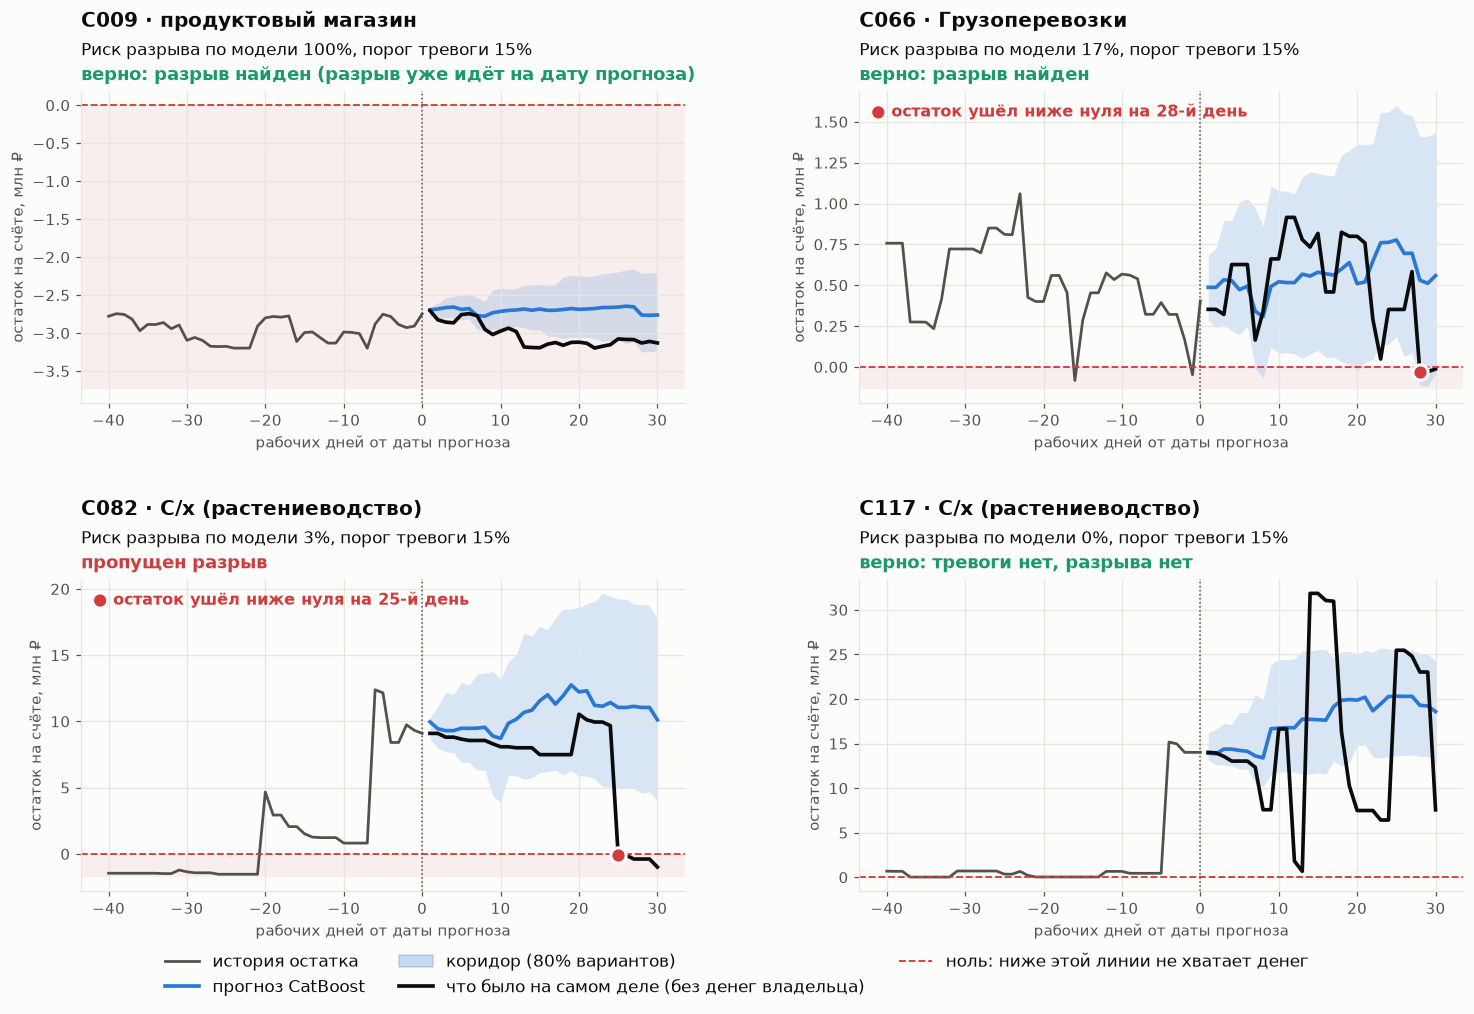

,компания,отрасль,"риск по модели, %",тревога,разрыв на деле,итог
0,C009,Розница: продуктовый магазин,100,да,был,верно: разрыв найден
1,C066,Грузоперевозки,17,да,был,верно: разрыв найден
2,C082,Сельское хозяйство (растениеводство),3,нет,был,пропущен разрыв
3,C117,Сельское хозяйство (растениеводство),0,нет,не было,"верно: тревоги нет, разрыва нет"


In [31]:
DEMO = ["C009", "C066", "C082", "C117"]          # демо-компании из сценария защиты
ALERT_THR = 0.15                                  # порог тревоги CatBoost, который выбирала кросс-валидация на других компаниях
cut_pos = {c: len(flows[c]) - 1 - H for c in DEMO}
CUT_DATE = min(flows[c].index[cut_pos[c]] for c in DEMO)

# итоговая модель: все компании, кроме демо, и только окна, которые заканчиваются раньше даты прогноза
d_train = [c for c in preps if c not in DEMO]
v_demo = set(np.random.default_rng(CFG["seed"]).choice(d_train, size=int(len(d_train) * CFG["val_frac"]), replace=False))
frames_d = [make_cum_rows(flows[c], INDUSTRY.get(c, "unknown"), step=CFG["train_step"], min_history=CFG["min_history"],
                          after_gap=gaps_mask[c], company=c, horizons=CFG["train_horizons"], max_target_date=CUT_DATE) for c in d_train]
all_d = pd.concat([f for f in frames_d if len(f)], ignore_index=True)
tr_d, va_d = all_d[~all_d["company"].isin(v_demo)], all_d[all_d["company"].isin(v_demo)]
lo_d, hi_d = tr_d["y"].quantile([0.005, 0.995])
tr_d, va_d = tr_d.assign(y=tr_d["y"].clip(lo_d, hi_d)), va_d.assign(y=va_d["y"].clip(lo_d, hi_d))
final_mean, final_q = fit_cb("RMSE", tr_d, va_d), fit_cb(Q_LOSS, tr_d, va_d)
print(f"Итоговая модель обучена на {tr_d['company'].nunique()} компаниях (ещё {va_d['company'].nunique()} для ранней остановки), "
      f"деревьев: {final_mean.tree_count_} и {final_q.tree_count_}. Дата прогноза: {CUT_DATE.date()}")

GREEN_, RED_ = "#1a9a6c", "#d03b3b"
short_ = lambda t: (t or "").replace("Сельское хозяйство", "С/х").replace("Розница: ", "")  # noqa: E731
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))
demo_rows = []
for ax, c in zip(axes.ravel(), DEMO):
    prep_, pos_ = preps[c], cut_pos[c]
    panel_, ops_ = prep_.panel.reset_index(drop=True), prep_.ops
    excl_ = ops_[ops_["category"].isin(EXCLUDED_FROM_FORECAST) & ops_["quality"].ne("duplicate")].groupby("operation_date")["signed"].sum()
    bal_ = panel_["balance"].to_numpy()
    inj_ = np.cumsum(panel_["date"].map(excl_).fillna(0.0).to_numpy())
    fact_ = (bal_ - (inj_ - inj_[pos_]))[pos_ + 1: pos_ + 1 + H]               # остаток без денег владельца после даты прогноза
    rows_ = make_cum_rows(flows[c], INDUSTRY.get(c, "unknown"), step=CFG["train_step"], min_history=CFG["min_history"],
                          after_gap=gaps_mask[c], company=c, positions=[pos_])
    rows_ = rows_[rows_["h"].le(H)].sort_values("h")
    sc_, b0_ = rows_["scale"].iloc[0], bal_[pos_]
    p50_ = b0_ + sc_ * final_mean.predict(X(rows_, True))
    q_ = b0_ + sc_ * np.sort(final_q.predict(X(rows_, True)), axis=1)
    risk_ = float(cb_prob(q_).max())
    alert_, gap_, ongoing_ = risk_ >= ALERT_THR, bool((fact_ < 0).any()), bool(b0_ < 0)
    verdict_, vcolor_ = (("верно: разрыв найден", GREEN_) if alert_ and gap_ else
                         ("верно: тревоги нет, разрыва нет", GREEN_) if not alert_ and not gap_ else
                         ("пропущен разрыв", RED_) if gap_ else ("ложная тревога", RED_))
    d_ = np.arange(1, H + 1)
    ax.axhspan(min(bal_[pos_ - 40: pos_ + 1].min(), fact_.min(), q_[:, 1].min(), 0) / 1e6 * 1.15, 0, color=RED_, alpha=0.07, lw=0)
    ax.plot(np.arange(-40, 1), bal_[pos_ - 40: pos_ + 1] / 1e6, color=INK2, lw=1.8)
    ax.fill_between(d_, q_[:, 1] / 1e6, q_[:, -2] / 1e6, color=PAL["CatBoost"], alpha=0.17, lw=0)
    ax.plot(d_, p50_ / 1e6, color=PAL["CatBoost"], lw=2.4)
    ax.plot(d_, fact_ / 1e6, color=INK, lw=2.4)
    ax.axhline(0, color=RED_, lw=1.2, ls="--")
    ax.axvline(0, color=INK2, lw=1, ls=":")
    neg_ = np.flatnonzero(fact_ < 0)
    if gap_ and not ongoing_ and len(neg_):
        ax.plot([d_[neg_[0]]], [fact_[neg_[0]] / 1e6], "o", ms=10, color=RED_, mec="white", mew=2, zorder=5)
        ax.text(0.02, 0.96, f"● остаток ушёл ниже нуля на {neg_[0] + 1}-й день", transform=ax.transAxes, fontsize=10.5,
                color=RED_, va="top", fontweight="bold")
    ax.set_xlabel("рабочих дней от даты прогноза")
    ax.set_ylabel("остаток на счёте, млн ₽")
    ax.set_title(f"{c} · {short_(INDUSTRY.get(c))}", loc="left", fontsize=13, fontweight="bold", pad=42)
    ax.text(0, 1.115, f"Риск разрыва по модели {risk_:.0%}, порог тревоги {ALERT_THR:.0%}", transform=ax.transAxes, fontsize=11, color=INK)
    ax.text(0, 1.035, verdict_ + (" (разрыв уже идёт на дату прогноза)" if ongoing_ else ""), transform=ax.transAxes,
            fontsize=11.5, color=vcolor_, fontweight="bold")
    demo_rows.append({"company": c, "industry": INDUSTRY.get(c), "risk_max_pct": round(100 * risk_), "alert": bool(alert_),
                      "gap_actual": gap_, "already_negative": ongoing_, "verdict": verdict_})
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Line2D([0], [0], color=INK2, lw=1.8, label="история остатка"),
                    Line2D([0], [0], color=PAL["CatBoost"], lw=2.4, label="прогноз CatBoost"),
                    Patch(color=PAL["CatBoost"], alpha=0.25, label="коридор (80% вариантов)"),
                    Line2D([0], [0], color=INK, lw=2.4, label="что было на самом деле (без денег владельца)"),
                    Line2D([0], [0], color=RED_, lw=1.2, ls="--", label="ноль: ниже этой линии не хватает денег")],
           loc="lower center", ncol=3, frameon=False, fontsize=11, bbox_to_anchor=(0.5, -0.005))
plt.tight_layout(rect=(0, 0.05, 1, 1), h_pad=3.2)
os.makedirs("experiments/out", exist_ok=True)
plt.savefig("experiments/out/catboost_demo.png", dpi=130, bbox_inches="tight")   # для сводного отчёта
json.dump(demo_rows, open("experiments/out/catboost_demo.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
plt.show()
pd.DataFrame(demo_rows).assign(alert=lambda d: d["alert"].map({True: "да", False: "нет"}),
                               gap_actual=lambda d: d["gap_actual"].map({True: "был", False: "не было"}))[
    ["company", "industry", "risk_max_pct", "alert", "gap_actual", "verdict"]].rename(columns={
        "company": "компания", "industry": "отрасль", "risk_max_pct": "риск по модели, %", "alert": "тревога",
        "gap_actual": "разрыв на деле", "verdict": "итог"})

## 14. Выводы

**Разрывы.** Ансамбль гибрида и CatBoost лучше остальных по ROC-AUC (0,90), PR-AUC (0,66) и Brier (0,089), F1 равен 0,59. Модели дополняют друг друга: гибрид знает будущие события компании (регулярные платежи, налоги, счета), CatBoost использует опыт других компаний. Порог тревоги около 25%, а не 50%: пропустить разрыв дороже, чем предупредить лишний раз.

**Остаток.** На 30 дней три модели ошибаются одинаково (около 21 дневного оборота). Причина в редких крупных платежах. Поэтому главное в сервисе это не точная сумма, а ответ на вопрос «когда, сколько и почему не хватит», плюс события, о которых знает пользователь.

**Категоризация.** Модель устойчива к опечаткам и сокращениям (macro-F1 0,95). Слабое место: непонятные операции уходят в «поставщиков». При низкой уверенности лучше помечать операцию как «не определено».

**Что можно улучшить:** калибровку коридора P10–P90 (покрытие сейчас 0,71–0,73 вместо 0,8), функцию потерь, устойчивую к крупным платежам, точность даты и суммы разрыва, оценку вклада каждого источника данных.

In [32]:
# служебная ячейка: сохраняем результаты для сборки отчёта
import pickle

pred_clean, conf_clean = clf.predict(text_clean)
pred_noisy, conf_noisy = clf.predict(text_noisy)
heavy = ["hyb_prob", "hyb_p10", "hyb_p50", "hyb_p90", "cb_q", "cb_mean", "cb_p10", "cb_p50", "cb_p90",
         "actual", "actual_oper", "ens_mean"]
STATE = {
    "C": C.drop(columns=[c for c in heavy if c in C.columns]),
    "W": W[["company", "industry", "cutoff", "scale", "bal0", "actual_oper", "hyb_p50", "cb_mean", "ens_mean", "fold"]],
    "CURVES": CURVES, "LC": LC, "FOLD_METRICS": FOLD_METRICS, "RET": RET,
    "CLF": CLF, "REG": REG, "FOLDS": FOLDS, "imp": imp, "curves": curves, "CAT": CAT,
    "cat": pd.DataFrame({"direction": te_l["direction"].values, "purpose": te_l["payment_purpose"].values,
                         "noisy": text_noisy.values, "true": te_l["category"].values, "pred_clean": pred_clean,
                         "conf_clean": conf_clean, "pred_noisy": pred_noisy, "conf_noisy": conf_noisy}),
    "cat_labels": {k: v.label for k, v in CATEGORIES.items()},
    "CV_PRED": CV_PRED, "THR": THR, "BEST": BEST, "y": y, "QS": QS,
}
os.makedirs("experiments/out", exist_ok=True)
pickle.dump(STATE, open("experiments/out/state.pkl", "wb"))